# 🍽️ Sprint 10 — Mercado de Restaurantes em Los Angeles
### por Luiz Trajano

---

## Contexto

Decidi abrir uma pequena cafeteria com garçons robôs em Los Angeles. É um projeto bem promissor,
mas caro, então eu e meus parceiros decidimos tentar atrair investidores. Eles estão interessados
nas condições atuais do mercado e querem saber se conseguiremos manter o sucesso quando a novidade
de garçons robôs esmorecer.

Meus parceiros me pediram para preparar uma pesquisa do mercado a partir de dados de código aberto
sobre restaurantes em LA. O entregável tem duas partes: **este notebook** (a análise) e uma
**apresentação em PDF** para os investidores, linkada na seção 4.

**A pergunta que a análise precisa responder:** que tipo de estabelecimento, com quantos assentos,
tem a melhor chance de se sustentar em LA depois que o efeito novidade passar — e vale a pena
pensar em rede?

## Índice

- [1. Carregamento e preparação dos dados](#1.-Carregamento-e-preparação-dos-dados)
- [2. Análise de dados](#2.-Análise-de-dados)
  - [2.1 Proporções dos tipos de estabelecimento](#2.1-Proporções-dos-tipos-de-estabelecimento)
  - [2.2 Proporções de rede e não-rede](#2.2-Proporções-de-rede-e-não-rede)
  - [2.3 Que tipo de estabelecimento é típico para redes](#2.3-Que-tipo-de-estabelecimento-é-típico-para-redes)
  - [2.4 O que caracteriza uma rede](#2.4-O-que-caracteriza-uma-rede)
  - [2.5 Número médio de assentos por tipo](#2.5-Número-médio-de-assentos-por-tipo)
  - [2.6 Extração do nome da rua](#2.6-Extração-do-nome-da-rua)
  - [2.7 As dez ruas com mais restaurantes](#2.7-As-dez-ruas-com-mais-restaurantes)
  - [2.8 Ruas com um único restaurante](#2.8-Ruas-com-um-único-restaurante)
  - [2.9 Distribuição de assentos nas ruas movimentadas](#2.9-Distribuição-de-assentos-nas-ruas-movimentadas)
- [3. Conclusão geral e recomendações](#3.-Conclusão-geral-e-recomendações)
- [4. Apresentação](#4.-Apresentação)

---

## Descrição dos dados — tabela `rest_data`

| coluna | descrição |
|---|---|
| `object_name` | nome do estabelecimento |
| `chain` | estabelecimento de rede (TRUE/FALSE) |
| `object_type` | tipo de estabelecimento |
| `address` | endereço |
| `number` | número de assentos |

> ⚠️ O arquivo traz também uma coluna `id` que **não está no dicionário oficial** acima. Primeira
> coisa a checar no Passo 1: ela é chave única? Serve pra alguma coisa na análise ou é ruído?

---

# 1. Carregamento e preparação dos dados

> **Enunciado:** Carregue os dados sobre restaurantes em LA. Certifique-se de que os tipos de dados
> para cada coluna estão corretos e não há valores ausentes ou duplicados. Processe-os, se necessário.

Antes de qualquer gráfico eu preciso confiar no dado. Vou seguir a mesma sequência que já uso desde
o Sprint 6 — visão geral → ausentes → duplicados → tipos → validade dos valores — e só depois abrir
o Passo 2. Cada bloco abaixo é uma checagem independente, e a conclusão do passo consolida o que
achei e o que decidi tratar.

In [420]:
# =============================================================================
# SETUP — bibliotecas, estilo pessoal e caminho do arquivo
# =============================================================================

# --- 1. Bibliotecas ----------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from cycler import cycler

# --- 2. Ajustes de exibição --------------------------------------------------
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# --- 3. Meu estilo visual ----------------------------------------------------
meu_estilo = {
    'figure.figsize':   (12, 5),
    'figure.facecolor': '#0d0d0d',
    'axes.facecolor':   '#0d0d0d',
    'savefig.facecolor':'#0d0d0d',
    'axes.edgecolor':   '#333333',
    'axes.labelcolor':  '#aaaaaa',
    'axes.titlecolor':  '#ffffff',
    'text.color':       '#aaaaaa',
    'xtick.color':      '#aaaaaa',
    'ytick.color':      '#aaaaaa',
    'grid.color':       '#222222',
    'axes.grid':        True,
    'axes.grid.axis':   'y',
    'axes.axisbelow':   True,
    'axes.prop_cycle':  cycler(color=['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']),
    'savefig.dpi':      150,
    'savefig.bbox':     'tight',
    'legend.facecolor': '#1a1a1a',
    'legend.edgecolor': '#333333',
}
sns.set_theme(style='dark', rc=meu_estilo)   # seaborn primeiro, meu rc por cima
plt.rcParams.update(meu_estilo)

# Paleta pro plotly, pra apresentação não trocar de identidade visual no meio
TEMPLATE_PLOTLY = 'plotly_dark'
CORES = ['#5B6BF5', '#FF6B6B', '#F5A623', '#4ECDC4', '#C77DFF']

# --- 4. Caminho do arquivo ---------------------------------------------------
# Variável `path` em vez de caminho hardcoded (regra do capítulo "Relatórios no
# Jupyter Notebook"): trocar uma linha muda o notebook inteiro de ambiente.
path = 'Data/rest_data_us_upd.csv'                     # local (VS Code)  <- ativo
# path = '/datasets/rest_data_us_upd.csv'              # plataforma TripleTen
# path = '/content/drive/MyDrive/rest_data_us_upd.csv' # Colab pessoal (+ drive.mount)

In [421]:
# -----------------------------------------------------------------------------
# 1.1 Visão geral — o que eu tenho na mão?
# -----------------------------------------------------------------------------
# Análise exploratória inicial dos dados que tenho.
# Gosto de utilizar também o .sample() para amostra aleatória.

rest = pd.read_csv(path)

print(rest.shape, '\n')

rest.info()
print()

print(rest.sample(5, random_state=42), '\n')   # random_state: mesma amostra a cada execução
display(rest.head(10))

print('id distintos:', rest['id'].nunique(), '| linhas:', len(rest))
print('id é chave única?', rest['id'].nunique() == len(rest))

# Ser chave única não quer dizer que o id SIGNIFIQUE alguma coisa. Se a faixa for
# contígua (sem buracos), ele é só um contador de linha com offset — não carrega
# informação de negócio, e duas linhas terem id diferente não prova nada sobre
# elas serem estabelecimentos diferentes. Isso importa lá no 1.3.
print('faixa de id:', rest['id'].min(), 'a', rest['id'].max())
print('faixa contígua, sem buracos?',
      rest['id'].max() - rest['id'].min() + 1 == len(rest))

(9651, 6) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9651 non-null   int64 
 1   object_name  9651 non-null   object
 2   address      9651 non-null   object
 3   chain        9648 non-null   object
 4   object_type  9651 non-null   object
 5   number       9651 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 452.5+ KB

         id          object_name               address  chain object_type  number
7746  19532   MY MOM'S BAKE SHOP      2434 W TEMPLE ST  False  Restaurant      27
4202  15988      MARISCOS CHENTE  4532 S CENTINELA AVE  False  Restaurant      32
6632  18418            HEADLINES     10922 KINROSS AVE  False  Restaurant      41
4639  16425          ZAMORA BROS      1559 W PICO BLVD  False  Restaurant      10
4825  16611  BLUE HEN RESTAURANT    1743 COLORADO BLVD   True  Restaurant      43 



,id,object_name,address,chain,object_type,number
0,11786,HABITAT COFFEE SHOP,3708 N EAGLE ROCK BLVD,False,Cafe,26
1,11787,REILLY'S,100 WORLD WAY 120,False,Restaurant,9
2,11788,STREET CHURROS,6801 HOLLYWOOD BLVD 253,False,Fast Food,20
3,11789,TRINITI ECHO PARK,1814 W SUNSET BLVD,False,Restaurant,22
4,11790,POLLEN,2100 ECHO PARK AVE,False,Restaurant,20
5,11791,THE SPOT GRILL,10004 NATIONAL BLVD,False,Restaurant,14
6,11792,CPK,100 WORLD WAY 126,False,Restaurant,100
7,11793,PHO LALA,3500 W 6TH ST STE 226,False,Restaurant,7
8,11794,ABC DONUTS,3027 N SAN FERNANDO RD UNIT 103,True,Fast Food,1
9,11795,UPSTAIRS,3707 N CAHUENGA BLVD,False,Restaurant,35


id distintos: 9651 | linhas: 9651
id é chave única? True
faixa de id: 11786 a 21436
faixa contígua, sem buracos? True


In [422]:
# -----------------------------------------------------------------------------
# 1.2 Valores ausentes
# -----------------------------------------------------------------------------
# Fazendo verificação de valores ausentes (missing values) e tomando decisões sobre eles.
# 1. .isna().sum() por coluna, e a mesma coisa em % do total
# verificação por linha que contiver com .any()

restaurant_missing = rest.isna().sum()
restaurant_missing_percent = (restaurant_missing / len(rest)) * 100

print("Valores ausentes por coluna:\n", restaurant_missing)
print("\nPercentual de valores ausentes por coluna:\n", restaurant_missing_percent.round(3))

restaurant_missing_rows = rest[rest.isna().any(axis=1)]
print("\nLinhas com valores ausentes:\n", restaurant_missing_rows)

Valores ausentes por coluna:
 id             0
object_name    0
address        0
chain          3
object_type    0
number         0
dtype: int64

Percentual de valores ausentes por coluna:
 id             0.000
object_name    0.000
address        0.000
chain          0.031
object_type    0.000
number         0.000
dtype: float64

Linhas com valores ausentes:
          id              object_name               address chain object_type  number
7408  19194  TAQUERIA LOS 3 CARNALES  5000 E WHITTIER BLVD   NaN  Restaurant      14
7523  19309     JAMMIN JIMMY'S PIZZA   1641 FIRESTONE BLVD   NaN       Pizza       1
8648  20434    THE LEXINGTON THEATER          129 E 3RD ST   NaN  Restaurant      35


In [423]:
# --- Decisão: dropar as 3 linhas --------------------------------------------
# São 3 linhas, todas na coluna `chain`, 0,03% da base. Preencher seria inventar
# dado: `chain` é declarado na fonte e não dá pra deduzir do nome nem do endereço
# (os três são estabelecimentos locais, sem outra unidade na base pra comparar).
# Dropo por dois motivos:
#   1. 0,03% não move nenhuma proporção do Passo 2;
#   2. sem NaN, `chain` vira bool de verdade no 1.4. Com NaN a coluna fica object,
#      e aí todo filtro `chain == True` depende de sorte em vez de tipo.
antes = len(rest)
rest = rest.dropna(subset=['chain']).copy()
print(f"\nLinhas removidas: {antes - len(rest)} | base agora: {len(rest)}")
print("Base sem nenhum ausente?", rest.isna().sum().sum() == 0)


Linhas removidas: 3 | base agora: 9648
Base sem nenhum ausente? True


In [424]:
# -----------------------------------------------------------------------------
# 1.3 Duplicados — explícitos, de chave e implícitos
# -----------------------------------------------------------------------------
# São TRÊS checagens diferentes, e eu preciso manter os nomes separados:
#   explícito -> a linha inteira repetida
#   de chave  -> mesmas colunas-chave (nome + endereço), id diferente
#   implícito -> a MESMA entidade escrita de outro jeito ("MCDONALD'S" vs "MCDONALDS")
# O que costuma me pegar é o implícito, porque ele infla a contagem de redes.

# --- 0. DUAS funções de normalização, e a diferença entre elas importa -------
# `normalizar()` — identidade de NOME. Resolve grafia:
#   - apóstrofo SOME:  MCDONALD'S -> MCDONALDS, WETZEL'S -> WETZELS
#   - resto da pontuação vira ESPAÇO: JACK-IN THE BOX -> JACK IN THE BOX
#   As duas são assimétricas de propósito: se eu trocasse apóstrofo por espaço,
#   "WETZEL'S" e "WETZELS" continuariam formas diferentes; se eu apagasse o hífen,
#   "JACK-IN" viraria "JACKIN" e não bateria com "JACK IN THE BOX".
#
# `chave()` — identidade de LUGAR. É `normalizar()` mais duas regras:
#   - "THE" inicial cai:  THE PRINCE == PRINCE
#   - "AND" vira espaço, para casar com o "&"
# Descobri que faltavam ao inspecionar o café no 2.3: sem elas a deduplicação
# deixava passar 14 pares de mesmo endereço.
#
# Por que SEPARADAS, e essa foi a lição mais cara do passo: eu tinha juntado tudo
# numa função só, e aí "THE CAFE" virou "CAFE". Como a regra da `marca` no 1.4
# corta número final quando o tronco existe como nome completo, "CAFE" passou a
# ser tronco válido e CAFE 100, CAFE 360, CAFE 607 e mais cinco viraram a MESMA
# marca — oito cafés distintos fundidos em silêncio.
# Duas linhas no mesmo endereço são o mesmo lugar com ou sem "THE"; duas marcas
# chamadas CAFE 360 e CAFE 100 são negócios diferentes. Conceitos diferentes
# pedem funções diferentes: `chave()` só deduplica, `normalizar()` faz o resto.
def normalizar(serie):
      return (serie.str.upper()
            .str.replace(r'[^\x00-\x7F]', '', regex=True)   # lixo de encoding
            .str.replace(r"['`´]", '', regex=True)          # apóstrofo some
            .str.replace(r'[^A-Z0-9 ]', ' ', regex=True)    # resto vira espaço
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip())


# Identidade de LUGAR: normalizar() + THE/AND. Usada SÓ para deduplicar.
def chave(serie):
      return (normalizar(serie)
            .str.replace(r'^THE ', '', regex=True)          # THE PRINCE == PRINCE
            .str.replace(r'\bAND\b', ' ', regex=True)       # "AND" casa com "&"
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip())


# --- 1. Duplicado explícito: linha inteira repetida --------------------------
# ATENÇÃO: rest.duplicated() puro incluiria a coluna `id`, que é chave única
# (1.1). O teste seria OBRIGADO a dar 0 e não checaria nada — um teste que não
# consegue falhar não é evidência. Tenho que tirar o id da comparação.
restaurant_duplicates = rest.drop(columns='id').duplicated().sum()

print(f"Duplicados explícitos (linha inteira, sem o id): {restaurant_duplicates}")
print(f"Linhas únicas: {len(rest) - restaurant_duplicates}")

# --- 2. Duplicado de chave: mesmo nome + mesmo endereço ----------------------
# A chave crua compara texto literal, então "STE 268A" e "STE #268A" passam
# batido. Comparo as duas versões pra ver o tamanho real do problema.
print(f"\nDuplicatas de chave CRUA (nome + endereço): "
      f"{rest.duplicated(subset=['object_name', 'address']).sum()}")

rest['_chave'] = chave(rest['object_name']) + ' || ' + chave(rest['address'])
print(f"Duplicatas de chave NORMALIZADA: {rest.duplicated(subset='_chave').sum()}")

# A contagem sozinha não decide nada. Preciso VER as linhas pra saber se é o mesmo
# lugar cadastrado duas vezes ou dois pontos no mesmo endereço (dois andares, dois
# terminais). keep=False mostra as duas pontas, não só a segunda ocorrência.
pares = rest[rest.duplicated(subset='_chave', keep=False)].sort_values(['_chave', 'id'])
print(f"\nLinhas envolvidas: {len(pares)} | grupos: {pares['_chave'].nunique()}")
display(pares[['id', 'object_name', 'address', 'chain', 'object_type', 'number']].head(20))

# O diagnóstico está no que difere DENTRO de cada par:
#   - bug de cópia   -> linhas idênticas e VIZINHAS no arquivo
#   - recoleta       -> `number` muda e os ids ficam LONGE um do outro
dif = pares.groupby('_chave').agg(assentos_min=('number', 'min'),
                              assentos_max=('number', 'max'),
                              gap_id=('id', lambda s: s.max() - s.min()))
dif['dif_assentos'] = dif['assentos_max'] - dif['assentos_min']

print(f"\nPares com `number` idêntico: {(dif['dif_assentos'] == 0).sum()} de {len(dif)}")
print(f"Diferença de assentos — mediana: {dif['dif_assentos'].median():.0f} "
      f"| máxima: {dif['dif_assentos'].max()}")
print(f"Distância entre os ids do par — mínima: {dif['gap_id'].min()} "
      f"| mediana: {dif['gap_id'].median():.0f}")

Duplicados explícitos (linha inteira, sem o id): 0
Linhas únicas: 9648



Duplicatas de chave CRUA (nome + endereço): 1
Duplicatas de chave NORMALIZADA: 56

Linhas envolvidas: 112 | grupos: 56


,id,object_name,address,chain,object_type,number
2308,14094,23RD ST CAFE,936 W 23RD ST,False,Restaurant,32
7454,19240,23RD ST. CAFE,936 W 23RD ST,False,Restaurant,35
3561,15347,5 STAR MARKET,2700 W VERNON AVE,False,Restaurant,28
7063,18849,5- STAR- MARKET,2700 W VERNON AVE,False,Restaurant,1
5059,16845,AUNTIE ANNE'S,3650 W MLK BLVD 268A,True,Restaurant,14
7772,19558,AUNTIE ANNE'S,3650 W MLK BLVD #268A,True,Restaurant,13
73,11859,BLD,700 WORLD WAY 7C,True,Restaurant,21
7115,18901,BLD,700 WORLD WAY 7C,True,Restaurant,26
161,11947,CARLS JR #212,1751 S SOTO ST,False,Restaurant,140
4984,16770,CARL'S JR #212,1751 S SOTO ST,True,Restaurant,106



Pares com `number` idêntico: 2 de 56
Diferença de assentos — mediana: 9 | máxima: 70
Distância entre os ids do par — mínima: 108 | mediana: 2818


In [425]:
# Leitura: ids nunca vizinhos + `number` quase sempre diferente = não é bug de
# duplicação, é o MESMO estabelecimento registrado em duas coletas distintas.
# Fico com o registro de id maior (o mais recente) e levo pro 3.5 a consequência
# que importa de verdade: `number` não é um valor estável, ele carrega ruído de
# medição — e é em cima dele que eu vou recomendar um número de assentos.
antes = len(rest)
rest = rest.sort_values('id').drop_duplicates(subset='_chave', keep='last')
rest = rest.drop(columns='_chave').reset_index(drop=True)
print(f"\nLinhas removidas: {antes - len(rest)} | base agora: {len(rest)}")


Linhas removidas: 56 | base agora: 9592


In [426]:
# --- 3. Duplicado implícito: mesma entidade, grafia diferente ----------------
restaurant_name_counts = rest['object_name'].value_counts()
print(f"\nNomes distintos: {restaurant_name_counts.shape[0]} (em {len(rest)} linhas)")

print("\nNomes que mais se repetem — são redes reais ou grafia inconsistente?")
print(restaurant_name_counts.head(10))

# Teste de normalização EM DEGRAUS. O upper/strip sozinho não serve de prova:
# o arquivo já vem em caixa alta e sem espaço nas pontas, então ele é obrigado a
# dar zero — de novo um teste que não consegue falhar. A duplicata implícita só
# aparece quando eu aperto o critério.
n_cru = rest['object_name'].nunique()
n_upper = rest['object_name'].str.upper().str.strip().nunique()
n_espaco = (rest['object_name'].str.upper()
            .str.replace(r'\s+', ' ', regex=True).str.strip().nunique())
n_pont = normalizar(rest['object_name']).nunique()

print(f"\nNomes distintos — cru: {n_cru} | upper+strip: {n_upper}"
      f" | + espaço duplo: {n_espaco} | + pontuação/encoding: {n_pont}")


Nomes distintos: 8640 (em 9592 linhas)

Nomes que mais se repetem — são redes reais ou grafia inconsistente?
object_name
THE COFFEE BEAN & TEA LEAF    45
SUBWAY                        31
KENTUCKY FRIED CHICKEN        14
WABA GRILL                    14
TRIMANA                       13
MCDONALD'S                    13
DOMINO'S PIZZA                13
STARBUCKS                     12
YOGURTLAND                    12
HONG KONG EXPRESS             12
Name: count, dtype: int64

Nomes distintos — cru: 8640 | upper+strip: 8640 | + espaço duplo: 8636 | + pontuação/encoding: 8593


In [427]:
# Quais nomes o critério mais forte funde? Preciso olhar pra confirmar que são
# a mesma marca, e não duas marcas que por acaso colidiram.
comp = pd.DataFrame({'cru': rest['object_name'], 'norm': normalizar(rest['object_name'])})
colisoes = comp.groupby('norm')['cru'].nunique()
colisoes = colisoes[colisoes > 1]
print(f"\nFormas normalizadas com mais de uma grafia crua: {len(colisoes)}")
for n in colisoes.head(8).index:
    print('  ', n, '->', sorted(set(comp.loc[comp['norm'] == n, 'cru'])))

# Encoding quebrado é duplicata implícita disfarçada: o mesmo McDonald's vira uma
# "marca" nova só porque o apóstrofo veio corrompido do arquivo de origem.
quebrados = rest['object_name'].str.contains(r'[^\x00-\x7F]', regex=True)
print(f"\nLinhas com caractere corrompido em object_name: {quebrados.sum()}")
print(rest.loc[quebrados, 'object_name'].tolist())

# Mesma checagem em object_type: categoria com grafia diferente vira categoria
# fantasma no gráfico do 2.1. Aqui só quero saber QUAIS categorias existem —
# a proporção entre elas é a pergunta do 2.1, não deste passo.
print("\nCategorias de object_type:", rest['object_type'].unique())
print('distintas — cru:', rest['object_type'].nunique(),
    '| normalizado:', normalizar(rest['object_type']).nunique())

# NOTA: a normalização acima resolve grafia, mas NÃO resolve o sufixo de loja
# ("SUBWAY #39685", "JACK IN THE BOX # 3348"), que é o que quebra a contagem de
# unidades por rede no 2.4. Isso vira a coluna `marca`, construída no 1.4.


Formas normalizadas com mais de uma grafia crua: 46
   BIG MAMAS PAPAS PIZZERIA -> ["BIG MAMA'S & PAPA'S PIZZERIA", 'BIG MAMAS & PAPAS PIZZERIA']
   BIONICOS DAISYS -> ["BIONICOS DAISY'S", 'BIONICOS DAISYS']
   CALIF PIZZA KITCHEN -> ['CALIF PIZZA KITCHEN', 'CALIF PIZZA KITCHEN #']
   CALIFORNIA PIZZA KITCHEN -> ['CALIFORNIA PIZZA KITCHEN', 'CALIFORNIA PIZZA KITCHEN #']
   CARLS JR -> ["CARL'S JR", "CARL'S JR."]
   CHIPOTLE MEXICAN GRILL -> ['CHIPOTLE  MEXICAN GRILL', 'CHIPOTLE MEXICAN GRILL']
   DOMINOS PIZZA -> ["DOMINO'S PIZZA", 'DOMINOS PIZZA']
   DUNKIN DONUTS -> ['DUNKIN DONUTS', "DUNKIN' DONUTS"]

Linhas com caractere corrompido em object_name: 4
['GREEN SPAN���S GRILLED CHEESE', 'L���ASSIETTE STEAK FRITES', 'JACOB���S MARKET', 'MCDONALD���S #1126']

Categorias de object_type: ['Cafe' 'Restaurant' 'Fast Food' 'Bakery' 'Bar' 'Pizza']
distintas — cru: 6 | normalizado: 6


In [428]:
# -----------------------------------------------------------------------------
# 1.4 Tipos de dados, a coluna `id` e a coluna `marca`
# -----------------------------------------------------------------------------
# Três coisas aqui: colocar cada coluna no tipo certo, decidir o que fazer com a
# coluna `id` (que está no arquivo mas não no dicionário oficial), e criar a
# coluna `marca` — que é a correção do problema que o 1.3 deixou apontado.

print('Tipos antes:')
print(rest.dtypes, '\n')

# --- 1. `chain` --------------------------------------------------------------
# Vinha como object só por causa dos NaN que dropei no 1.2 — os valores em si já
# eram bool de Python. Sem os NaN, a coluna assume o tipo de verdade, e aí
# `chain == True` passa a ser garantia de tipo em vez de sorte.
print('valores em chain:', rest['chain'].unique())
rest['chain'] = rest['chain'].astype(bool)

# --- 2. `number` -------------------------------------------------------------
# Já é int64. Se tivesse vindo float, seria sinal de ausente na leitura (o pandas
# promove pra float quando encontra NaN numa coluna numérica).
print('number é inteiro?', pd.api.types.is_integer_dtype(rest['number']))

# --- 3. `object_type` --------------------------------------------------------
# 6 categorias fixas repetidas em ~9,6 mil linhas: category economiza memória e
# deixa explícito que é categórica, não texto livre.
rest['object_type'] = rest['object_type'].astype('category')

Tipos antes:
id              int64
object_name    object
address        object
chain          object
object_type    object
number          int64
dtype: object 

valores em chain: [False True]
number é inteiro? True


In [429]:
# --- 4. `id` -----------------------------------------------------------------
# Chave única E faixa contígua (1.1): é um contador de linha, não um dado de
# negócio. Fica na tabela pra eu rastrear uma linha até o CSV original, mas NÃO
# entra em nenhum groupby, contagem ou gráfico do Passo 2.
id_unique = rest['id'].nunique()
print(f"\nNúmero de IDs distintos: {id_unique} (em {len(rest)} linhas)")
print(f"ID é chave única? {id_unique == len(rest)}")

# --- 5. `marca` — a coluna que o 1.3 mostrou que faltava ---------------------
# O problema: parte dos nomes carrega o número da loja ("SUBWAY #39685",
# "JACK IN THE BOX # 3348"). Agrupar por `object_name` faria cada loja virar uma
# rede de 1 unidade — e o 2.4 pergunta exatamente quantas unidades uma rede tem.
# O tamanho disso é MEDIDO no fim desta célula, não afirmado de cabeça.
#
# Regra em duas partes, porque número no fim do nome é AMBÍGUO:
#   (a) veio com '#'  -> é número de loja sem discussão, corta;
#   (b) número solto  -> só corto SE o tronco já existir como nome completo em
#       outra linha. "SUBWAY 46382" vira SUBWAY porque SUBWAY existe sozinho;
#       "CAFE 360", "FOREVER 21", "PHO 2000" e "FRED 62" ficam intactos, porque
#       ali o número é parte do nome, não a loja nº 360.
nome_norm = normalizar(rest['object_name'])          # função definida no 1.3
tem_hash = rest['object_name'].str.contains(r'#\s*\d', regex=True)
tronco = nome_norm.str.replace(r'\s\d{1,5}[A-Z]?$', '', regex=True)

eh_sufixo = tem_hash | (tronco.isin(set(nome_norm)) & tronco.ne(nome_norm))
rest['marca'] = tronco.where(eh_sufixo, nome_norm)

# --- 5b. Variantes de nome comercial ----------------------------------------
# A regra acima resolve pontuação e número de loja, mas não resolve a mesma marca
# escrita de outro jeito. Encontrei isso inspecionando o café no 2.3 e voltei aqui,
# porque `marca` tem que sair PRONTA deste passo — o 2.4 é construído em cima dela.
#
# A ORDEM aqui é crítica. O "THE" só pode cair DEPOIS do teste (b) acima, nunca
# antes: se `nome_norm` já viesse sem "THE", o nome "THE CAFE" viraria "CAFE",
# "CAFE" passaria a ser tronco válido, e CAFE 100 / CAFE 360 / CAFE 607 seriam
# cortados como se fossem lojas da mesma marca. Aplicando depois, o teste (b)
# compara contra os nomes como eles são, e esses cafés sobrevivem.
rest['marca'] = (rest['marca']
                 .str.replace(r'^THE ', '', regex=True)     # THE FLAME BROILER
                 .str.replace(r'\bAND\b', ' ', regex=True)  # PEETS COFFEE AND TEA
                 .str.replace(r'\s+', ' ', regex=True)
                 .str.strip())

# O que regra nenhuma pega sem risco: descritor comercial no fim do nome
# (STARBUCKS COFFEE / STARBUCKS). Dicionário explícito para ficar auditável — uma
# regra que cortasse a última palavra fundiria marcas diferentes em silêncio.
# É também o limite desta correção: só consolidei o que encontrei olhando café,
# então variantes desse tipo podem sobrar em categorias que não inspecionei.
CONSOLIDA = {
    'STARBUCKS COFFEE': 'STARBUCKS',
}
rest['marca'] = rest['marca'].replace(CONSOLIDA)

print(f"\nnomes distintos (object_name): {rest['object_name'].nunique()}")
print(f"marcas distintas (marca)     : {rest['marca'].nunique()}")

# O tamanho do problema, medido. Sobre a base inteira ele parece modesto; o que
# importa é o peso DENTRO das redes, porque é ali que o 2.4 vai contar unidades.
n_sufixo = eh_sufixo.sum()
n_sufixo_rede = eh_sufixo[rest['chain']].sum()
print(f"\nLinhas com sufixo de loja no nome: {n_sufixo}"
      f" ({n_sufixo / len(rest) * 100:.1f}% da base)")
print(f"  dessas, em linhas de rede: {n_sufixo_rede}"
      f" ({n_sufixo_rede / rest['chain'].sum() * 100:.1f}% das linhas com chain=True)")


Número de IDs distintos: 9592 (em 9592 linhas)
ID é chave única? True

nomes distintos (object_name): 8640
marcas distintas (marca)     : 7773

Linhas com sufixo de loja no nome: 1005 (10.5% da base)
  dessas, em linhas de rede: 717 (19.7% das linhas com chain=True)


In [430]:
# Conferência dos dois lados da regra (b) — é aqui que ela se prova ou se quebra.
# Uma regra dessas erra em duas direções opostas, então testo as duas:
#   lista 1 -> o que ela CORTOU  (erro possível: cortar nome legítimo)
#   lista 2 -> o que ela MANTEVE (erro possível: deixar passar nº de loja)
# Juntas, as duas cobrem todo nome sem '#' terminado em número — é auditoria
# completa da regra (b), não amostra.
fundidos = (pd.DataFrame({'cru': rest['object_name'], 'marca': rest['marca']})
            [(~tem_hash) & eh_sufixo].drop_duplicates())
print(f"\n(1) Fundidos por número solto ({len(fundidos)}) —"
      f" se algum NÃO for nº de loja, a regra está agressiva:")
print(fundidos.head(12).to_string(index=False))

preservados = rest.loc[(~tem_hash)
                       & nome_norm.str.contains(r'\s\d{1,5}[A-Z]?$', regex=True)
                       & (~eh_sufixo), 'object_name'].unique()
print(f"\n(2) Nomes com número preservados ({len(preservados)}) —"
      f" se algum FOR nº de loja, a regra está frouxa:")
print(sorted(preservados)[:12])


(1) Fundidos por número solto (36) — se algum NÃO for nº de loja, a regra está agressiva:
                     cru               marca
           SUBWAY -52105              SUBWAY
          COFFEE HOUSE 1        COFFEE HOUSE
 SUBWAY SANDWICHES 13941   SUBWAY SANDWICHES
            SUBWAY 46382              SUBWAY
            SUBWAY 46383              SUBWAY
              UPSTAIRS 2            UPSTAIRS
     TEJUINOS RIVERA - 2     TEJUINOS RIVERA
           QUIZNO'S 5608             QUIZNOS
            SUBWAY-48844              SUBWAY
            NATUREWELL 2          NATUREWELL
      EL POLLO LOCO 3526       EL POLLO LOCO
EDIBLE ARRANGEMENTS-1003 EDIBLE ARRANGEMENTS

(2) Nomes com número preservados (91) — se algum FOR nº de loja, a regra está frouxa:
['AMC CENTURY CITY 15 LEVEL 1', 'AMC DINE-IN SUNSET 5', 'APARTMENT 503', 'ARAMARK CAFE/FOREVER 21', 'AVENUE 2', 'BACK HOUSE/KITCHEN 28', 'BACKYARD 4518', 'BAK KUNG KOREAN BBQ 2', 'BELLA TRATTORIA 25', 'BIG 8', 'BOARDWALK 11', 'BOULEVARD 

In [431]:
# Quais marcas mais agregam grafias diferentes? É o ganho concreto da coluna.
top_marcas = rest.groupby('marca')['object_name'].nunique().sort_values(ascending=False)
print("\nMarcas que mais agregam grafias distintas:")
print(top_marcas.head(8))

print('\nTipos depois:')
print(rest.dtypes)


Marcas que mais agregam grafias distintas:
marca
STARBUCKS          106
SUBWAY              90
MCDONALDS           67
JACK IN THE BOX     48
BURGER KING         38
PIZZA HUT           29
EL POLLO LOCO       27
TACO BELL           24
Name: object_name, dtype: int64

Tipos depois:
id                int64
object_name      object
address          object
chain              bool
object_type    category
number            int64
marca            object
dtype: object


In [432]:
# -----------------------------------------------------------------------------
# 1.5 Validade dos valores — o dado é plausível?
# -----------------------------------------------------------------------------
# Tipo certo e sem ausente ainda não quer dizer dado bom. Aqui eu procuro valor
# que é tecnicamente válido mas impossível no mundo real

# --- 1. `number` — resumo e os dois extremos --------------------------------
print(rest['number'].describe(), '\n')
print('zeros:', (rest['number'] == 0).sum(), '| negativos:', (rest['number'] < 0).sum())

# O zero era a minha suspeita lá no 1.2: `number` = 0 seria "não informado"
# fantasiado de valor real, e isso contaminaria a média do 2.5. Se o mínimo for
# >= 1, a suspeita morre aqui e a média não precisa de tratamento por esse motivo.

# --- 2. Existe teto artificial? ----------------------------------------------
# Se a fonte truncasse assentos num limite, eu veria EMPILHAMENTO no valor máximo
# — muitas linhas exatamente no teto e poucas logo abaixo. Se a contagem nos
# maiores valores for parelha, o máximo é real e não um corte da coleta.
print('\nContagem nos 10 maiores valores de `number`:')
print(rest['number'].value_counts().sort_index().tail(10))
print('\nQuantis altos:')
print(rest['number'].quantile([0.90, 0.95, 0.99, 1.0]))

# --- 3. `object_type` — alguma categoria pequena demais? --------------------
# Juntar ou manter separada é decisão MINHA e tem que estar justificada. Absoluto
# e relativo juntos, senão eu não sei se 283 é pouco ou muito.
print('\nContagem por tipo:')
print(rest['object_type'].value_counts())
print('\nEm %:')
print((rest['object_type'].value_counts(normalize=True) * 100).round(2))

count    9592.000000
mean       43.742285
std        47.684387
min         1.000000
25%        14.000000
50%        27.000000
75%        46.000000
max       229.000000
Name: number, dtype: float64 

zeros: 0 | negativos: 0

Contagem nos 10 maiores valores de `number`:
number
220     4
221     5
222     6
223     3
224     6
225    12
226     6
227     8
228     6
229     9
Name: count, dtype: int64

Quantis altos:
0.90    120.00
0.95    148.00
0.99    214.09
1.00    229.00
Name: number, dtype: float64

Contagem por tipo:
object_type
Restaurant    7217
Fast Food     1060
Cafe           426
Pizza          314
Bar            292
Bakery         283
Name: count, dtype: int64

Em %:
object_type
Restaurant    75.24
Fast Food     11.05
Cafe           4.44
Pizza          3.27
Bar            3.04
Bakery         2.95
Name: proportion, dtype: float64


In [433]:
# --- 4. `address` — o que vai quebrar o parsing de rua do 2.6 ---------------
comprimento = rest['address'].str.len()
print('\nComprimento de address — min:', comprimento.min(), '| max:', comprimento.max())

print('\nMais curtos:')
display(rest.loc[comprimento.nsmallest(5).index, ['object_name', 'address']])
print('Mais longos:')
display(rest.loc[comprimento.nlargest(5).index, ['object_name', 'address']])

# A regra que eu pretendo usar no 2.6 é "<número> <rua>". Endereço que NÃO começa
# com número quebra essa regra — quero saber quantos são ANTES de escrever o
# parsing, não depois que o gráfico do 2.7 sair estranho.
sem_numero = ~rest['address'].str.match(r'^\d')
print(f"\nEndereços que NÃO começam com número: {sem_numero.sum()}")
display(rest.loc[sem_numero, ['object_name', 'address']])


Comprimento de address — min: 8 | max: 44

Mais curtos:


,object_name,address
6877,KIKKA @ LMU,1 LMU DR
7070,ROSE & VINE,724 VINE
337,J AND P DELI,307 6TH ST
590,LITTLE JEWEL OF NEW ORLEANS,207 ORD ST
1252,LE PAIN QUOTIDIEN,509 6TH ST


Mais longos:


,object_name,address
7906,GULFSTREAM,10250 CALIFORNIA STATE ROUTE 2 BLVD STE #656
8948,BALDWIN HILL CRENSHAW PLAZA,3650 W MARTIN LUTHER KING JR. BLVD STE 243
7097,MCDONALD'S #28776,3650 W MARTIN LUTHER KING JR BLVD STE 271
9170,TASO TACO TACO,1030 W MARTIN LUTHER KING JR BLVD STE 108
8678,MAKO SUSHI RESTAURANT,123 ASTRONAUT ELLISON ONIZUKA ST STE 307



Endereços que NÃO começam com número: 8


,object_name,address
1878,MAGDALENO DEBBIE,OLVERA ST E17
3697,LAS ANITAS,OLVERA ST 26
7240,CIELITO LINDO,OLVERA ST 23
7277,JUANITA'S CAFE,OLVERA ST 20
7279,KITTY'S SNOW CONES,OLVERA ST 2
7285,LA NOCHE BUENA,OLVERA ST E8
7392,LA GOLONDRINA,OLVERA ST W17
7690,RODOLFO'S RESTAURANT,OLVERA ST 5


In [434]:
# checagem final: nenhuma linha com NaN, nenhuma duplicata explícita ou de chave,
#  tipo certo em `chain`, `number` >= 1 e `marca` não vazia.

# Sample de novo para ver o que temos

rest.info()
display(rest.sample(10, random_state=42))

# As decisões do Passo 1, verificadas em vez de assumidas. Se alguma quebrar numa
# reexecução, o notebook para aqui em vez de seguir com dado torto pro Passo 2.
assert rest.isna().sum().sum() == 0, 'sobrou valor ausente'
assert not rest.drop(columns='id').duplicated().any(), 'sobrou duplicata explícita'
assert not rest.duplicated(subset=['object_name', 'address']).any(), 'sobrou duplicata de chave'
assert rest['chain'].dtype == bool, 'chain não é booleana'
assert rest['number'].min() >= 1, 'number com zero ou negativo'
assert (rest['marca'].str.len() > 0).all(), 'marca vazia em alguma linha'
print('Checagens do Passo 1: todas passaram.')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9592 entries, 0 to 9591
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   id           9592 non-null   int64   
 1   object_name  9592 non-null   object  
 2   address      9592 non-null   object  
 3   chain        9592 non-null   bool    
 4   object_type  9592 non-null   category
 5   number       9592 non-null   int64   
 6   marca        9592 non-null   object  
dtypes: bool(1), category(1), int64(2), object(3)
memory usage: 393.8+ KB


,id,object_name,address,chain,object_type,number,marca
5148,16964,STARBUCKS COFFEE #13397,1149 S HILL ST,True,Cafe,36,STARBUCKS
7794,19631,GENERAL LEES (1ST FLOOR),475 GIN LING WAY,True,Restaurant,46,GENERAL LEES 1ST FLOOR
39,11825,TROPICAL FRUITS & JUICES,5729 N FIGUEROA ST,False,Restaurant,14,TROPICAL FRUITS JUICES
2766,14568,SAWTELLE TEMPURA HOUSE,1816 SAWTELLE BLVD,False,Restaurant,18,SAWTELLE TEMPURA HOUSE
1840,13636,DAVENPORTS CAFE,3965 WESTERN AVE,False,Restaurant,47,DAVENPORTS CAFE
5277,17093,VAKA BURGER EXPRESS,2765 E OLYMPIC BLVD,False,Fast Food,14,VAKA BURGER EXPRESS
5395,17213,CURRY HOUSE-KOREATOWN,621 S WESTERN AVE STE #208B,True,Restaurant,40,CURRY HOUSE KOREATOWN
9295,21140,CHITCHAT COFFEE,1854 SAWTELLE BLVD STE 101,False,Cafe,20,CHITCHAT COFFEE
1346,13139,FILIPINO BAGNET LOS ANGELES,3253 BEVERLY BLVD,False,Restaurant,23,FILIPINO BAGNET LOS ANGELES
1056,12849,LEDLOW,400 S MAIN ST,False,Restaurant,130,LEDLOW


Checagens do Passo 1: todas passaram.


**📝 Conclusão do Passo 1 — qualidade dos dados:**

**Dos dados que tínhamos anteriormente e o que temos agora.** Comecei com 9.651 linhas ×
6 colunas e terminei com 9.592 × 7. A coluna a mais é `marca`, criada no 1.4. O `id` é
chave única (9.651 valores distintos em 9.651 linhas), mas isso garante que cada
*registro* é único, não que cada *estabelecimento* é: os 56 pares que achei no 1.3
mostram exatamente essa diferença. O grão só passou a ser um estabelecimento por linha
depois da deduplicação. E chave única também não é a mesma coisa que informação: a faixa
é contígua, sem buracos, o que faz do `id` um contador de linha com offset. Ele fica na
tabela para eu rastrear uma linha até o CSV original, e não entra em nenhum groupby ou
gráfico.

**Ausentes: 3 linhas, todas em `chain`** (0,03% da base). Dropei em vez de preencher.
`chain` é declarado na fonte e não dá para deduzir do nome nem do endereço. Os três são
estabelecimentos locais, sem outra unidade na base para comparar, então preencher seria
inventar dado. Além disso, sem NaN a coluna assume `bool` de verdade, e aí todo filtro
`chain == True` passa a ser garantia de tipo em vez de sorte.

**Duplicados: os três tipos, e o que cada um revelou.**

- *Explícitos:* zero. Vale registrar como cheguei nesse zero: o teste tem que excluir o
  `id`, se não ele compara uma chave única e é obrigado a dar 0 sem checar nada.
- *De chave:* a chave crua (`object_name` + `address`) achou 1 caso. Comparando o mesmo
  par com o texto normalizado, achei **56**. As outras 55 diferiam por pontuação,
  espaçamento ou pelo artigo inicial: `AUNTIE ANNE'S` no `3650 W MLK BLVD 268A` e no
  `268A` com cerquilha, `CHINA EXPRESS` no `8522 S WESTERN AVE B` e no `#B`, e
  `THE PRINCE` / `PRINCE` no mesmo `3198 W 7TH ST`. Esse último me obrigou a separar
  duas funções que eu tinha juntado numa só: a chave de LUGAR pode cortar o "THE" e
  casar "AND" com "&"; a de NOME não pode. Quando eu cortava o "THE" também no nome,
  "THE CAFE" virava "CAFE", e isso arrastava `CAFE 360`, `CAFE 100` e mais seis para
  uma marca que não existe. Duas linhas no mesmo endereço são o mesmo lugar com ou sem
  artigo; duas marcas chamadas `CAFE 360` e `CAFE 100` são negócios diferentes.
- *Implícitos:* o teste de `upper`/`strip` não achou nada (8.640 antes e depois), e isso
  não é prova de qualidade, é limitação do teste: o arquivo já vem em caixa alta e sem
  espaço nas pontas, então ele só podia dar zero. Apertando o critério, os nomes distintos
  caem para 8.636 (espaço duplo) e 8.593 (pontuação e encoding). São 46 formas com mais de
  uma grafia, incluindo 4 linhas com apóstrofo corrompido na origem (`MCDONALD���S #1126`).

**O diagnóstico dos 56 pares foi o achado mais importante do passo.** Em 54 deles o número
de assentos é *diferente* entre as duas linhas: mediana de 9 assentos de diferença,
máxima de 70. E os dois registros nunca são vizinhos no arquivo: a distância mínima entre
os `id` do par é 108 e a mediana é 2.818. Isso descarta bug de duplicação, que geraria
linhas idênticas e coladas. O que sobra é o mesmo estabelecimento registrado em duas
coletas distintas, com recontagem de assentos entre elas. Fiquei com o registro de `id`
maior, o mais recente.

O que eu entendo disso importa mais que a limpeza em si: **`number` não é um valor
estável.** Quando o mesmo lugar foi medido duas vezes, a contagem mudou em 9 assentos na
mediana; num dos pares, em 70. Não é erro de digitação, é a natureza do dado. Qualquer
recomendação de tamanho que eu faça carrega essa margem.

Um detalhe que apareceu no meio dos 56 pares e vale anotar: em alguns deles, além dos
assentos, o próprio `chain` diverge: o mesmo `CARL'S JR #212` aparece como `False` numa
linha e `True` na outra. Ou seja, a flag de rede também é declarada, não derivada, e não é
perfeitamente consistente.

**Tipos.** `chain` era `object` só por causa dos NaN; virou `bool`. `object_type` virou
`category` (6 categorias fixas em 9,6 mil linhas). `number` já era `int64`. Se tivesse
vindo `float`, seria sinal de ausente na leitura.

**Uma coluna nova: `marca`.** O 1.3 mostrou um problema que a normalização de texto não
resolve: parte dos nomes carrega o número da loja (`SUBWAY #39685`, `JACK IN THE BOX #
3348`). São 1.005 linhas, 10,5% da base, mas **19,7% das linhas de rede**, quase o dobro
do peso. Diluído no total o problema parece pequeno; concentrado onde as redes estão, ele
é grande. Agrupar por `object_name` faria cada loja virar uma marca de uma unidade só.
Criei `marca` com uma regra em duas partes: nome com `#` tem o número cortado sem
discussão; número solto só é cortado se o tronco já existir como nome completo em outra
linha. É esse segundo critério que preserva `BOULEVARD 3`, `AVENUE 2` e `BELLA TRATTORIA
25`, onde o número faz parte do nome. Conferi os dois lados: 36 nomes cortados, 91
preservados. Resultado: 8.640 nomes viram 7.773 marcas. `object_name` continua intacto:
quem responde por estabelecimento usa ele, quem responde por rede usa `marca`.

**Valores implausíveis: não achei.** `number` vai de 1 a 229, sem zero e sem negativo, o
que mata a suspeita de "zero disfarçado de ausente" que eu levantei no 1.2. E não há teto
artificial: as contagens nos dez maiores valores ficam entre 3 e 12, sem empilhamento no
229. Isso significa que os valores altos são reais, não corte de coleta, e portanto não
são outlier para descartar.

O que eles são é outra coisa: a média (43,7) está bem acima da mediana (27), e o
desvio-padrão (47,7) é maior que a própria média. A distribuição é assimétrica à direita:
metade dos estabelecimentos tem 27 assentos ou menos, mas os 10% maiores passam de 120.
Média sozinha descreveria um estabelecimento que quase não existe.

**Uma pendência que o dado deixa clara.** O `address` serviu para comparar, mas não está
pronto para virar nome de rua. Eu já normalizei o endereço uma vez (foi o que fez as
duplicatas de chave saírem de 1 para 56), mas usei essa versão limpa só como chave
temporária e descartei; a coluna `address` continua crua. E ela traz três coisas que uma
extração de rua vai encontrar pela frente: oito endereços não começam com número (todos na
OLVERA ST), o sufixo de sala fica grudado no fim (`STE #656`, `STE 243`), e entre os
endereços mais longos a mesma via aparece com e sem o ponto no `JR`. No nível do
estabelecimento isso não atrapalhou: são prédios diferentes, salas diferentes. Só passa a
atrapalhar quando o número e a sala saírem e sobrar só o nome da rua.

**Posso confiar nesse dado para recomendar a um investidor?** Para as perguntas de
composição (tipo de estabelecimento, rede vs. independente, tamanho típico), sim: as
remoções somaram 59 linhas, 0,61% da base, e nenhuma proporção se move de forma
perceptível. Para a recomendação de **número de assentos**, confio na ordem de grandeza,
não no valor exato: o mesmo estabelecimento medido duas vezes chegou a variar 70 assentos.
O caminho honesto é recomendar uma faixa e dizer por quê, em vez de fingir uma precisão
que o dado não tem.


---

# 2. Análise de dados

Com o dado limpo, agora respondo uma pergunta do enunciado por vez. Cada sub-seção tem a pergunta
literal, o código, e a minha conclusão daquela pergunta — não deixo conclusão acumulada pro final.

**Sobre a escolha de biblioteca:** seaborn é obrigatório neste projeto e é o meu padrão aqui.
Matplotlib entra por baixo (`plt.figure()`, títulos, anotações) e plotly entra quando a
interatividade agrega de verdade — proporção com pizza e ranking com muitas categorias. Não uso
plotly só porque sei usar; se o gráfico estático conta a história melhor, ele fica.

> **Regra que vou seguir em todo gráfico daqui pra baixo:** o título entrega a **conclusão**, não
> descreve o dado. "Cafés dominam LA com 4 em cada 10 estabelecimentos", não "Contagem por tipo".
> É a regra do capítulo *Preparando Apresentações* e é o que entendo comparando como gráfico de analista de gráfico
> de planilha.

### 2.1 Proporções dos tipos de estabelecimento

> **Enunciado:** Investigue as proporções de vários tipos de estabelecimentos. Construa um gráfico.

Vou olhar como o mercado de LA se divide por tipo. Isso é uma pergunta de **composição**
(parte-do-todo), então a escolha real é entre barra ordenada e pizza — e essa escolha eu preciso
justificar, não chutar.

In [435]:
# -----------------------------------------------------------------------------
# 2.1 Proporções dos tipos de estabelecimento
# -----------------------------------------------------------------------------
# Passo 1 — os números. Absoluto e relativo lado a lado: "434 cafés" sozinho não
# diz se é muito, "4,5%" sozinho não diz se a base é grande o bastante pra
# confiar. Juntos, dizem as duas coisas.

tipos = pd.DataFrame({
    'estabelecimentos': rest['object_type'].value_counts(),
    'proporcao_%': (rest['object_type'].value_counts(normalize=True) * 100),
})
display(tipos)

# O número que decide o gráfico. Registrei no comentário acima que pizza só vale
# com 2 a 4 categorias — então esse print é o critério se aplicando, não eu
# escolhendo depois de ver o resultado.
print('categorias:', len(tipos),
    '| soma das proporções:', round(tipos['proporcao_%'].sum()))


,estabelecimentos,proporcao_%
object_type,,
Restaurant,7217,75.239783
Fast Food,1060,11.050876
Cafe,426,4.441201
Pizza,314,3.273561
Bar,292,3.044204
Bakery,283,2.950375


categorias: 6 | soma das proporções: 100


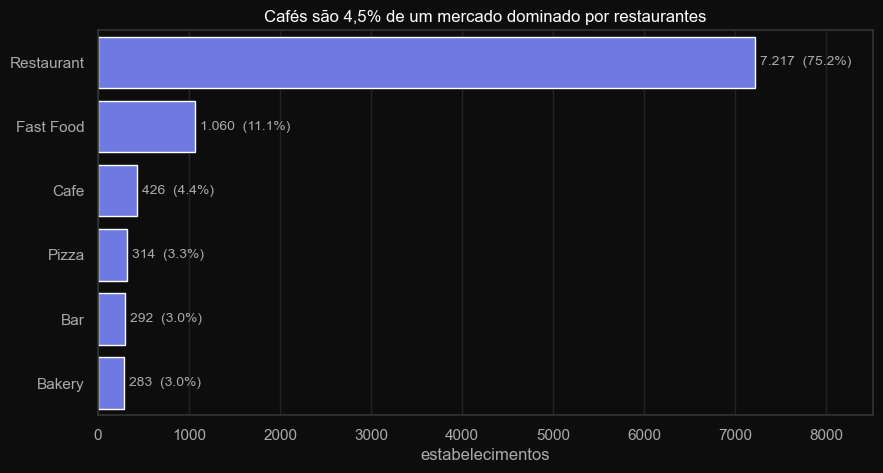

In [436]:
# Passo 2 — o gráfico. Barra HORIZONTAL porque nome de categoria é palavra, e
# palavra se lê na horizontal sem precisar girar rótulo. Gráfico de pizza ficaria
# distoante e pequeno de interpretar no âmbito dos cafés

plt.figure(figsize=(10, 5))

# `object_type` é category, e o seaborn ordena pelas categorias do DTYPE
# (alfabética), não pela ordem das linhas do `tipos`. Sem declarar a ordem, as
# barras saem alfabéticas e o bar_label — que cola por POSIÇÃO — desalinha.
# order= resolve as duas coisas de uma vez: alinha os rótulos e me dá o ranking.

ordem = tipos.index.tolist()          # já vem decrescente do value_counts

ax = sns.barplot(
    data=tipos.reset_index(),
    x='estabelecimentos',
    y='object_type',
    order=ordem,                      
    color=CORES[0],
    orient='h',
)

rotulos = [f'{n:,}'.replace(',', '.') + f'  ({p:.1f}%)'
        for n, p in zip(tipos['estabelecimentos'], tipos['proporcao_%'])]
ax.bar_label(ax.containers[0], labels=rotulos, padding=4, fontsize=10)

ax.set_xlim(0, tipos['estabelecimentos'].max() * 1.18)
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
ax.set_xlabel('estabelecimentos')
ax.set_ylabel('')
ax.set_title('Cafés são 4,5% de um mercado dominado por restaurantes')

plt.savefig('images/2_1_tipos_estabelecimento.png')
plt.show()


**📝 Conclusão 2.1 — tipos de estabelecimento:**

**O mercado de LA é de restaurantes, e não por pouco.** `Restaurant` sozinho é 7.217 dos
9.592 estabelecimentos: 75,2%, três em cada quatro. Somado a `Fast Food` (1.060, 11,0%),
os dois tipos respondem por 86,3% da cidade. As outras quatro categorias juntas
(`Cafe`, `Pizza`, `Bar` e `Bakery`) somam 1.315 estabelecimentos, 13,7% do total. Não
tenho outras cidades nesta base para comparar, então não sei dizer se essa concentração
é característica de LA ou o padrão de grandes cidades americanas. Fica como pergunta
em aberto.

**A distribuição é concentrada, não espalhada.** Não é o caso de seis categorias
disputando fatias parecidas: é uma categoria dominante e uma cauda. A diferença entre a
primeira e a segunda (64 pontos percentuais) é maior que a segunda inteira.

**Escolha do gráfico:** contei as categorias antes de decidir e deu 6, acima do limite de
2 a 4 que eu tinha registrado para pizza; então barra ordenada, porque comparar
comprimento é mais fácil que comparar ângulo. Na prática isso importa justamente na parte
de baixo do gráfico: `Pizza` (3,3%), `Bar` (3,0%) e `Bakery` (2,9%) ficariam a menos de
meio grau de diferença numa pizza, indistinguíveis. Em barra, o rótulo resolve.

**E sobre abrir uma cafeteria.** `Cafe` são 426 estabelecimentos, 4,4% do mercado, cerca de
um em cada 22. Dois jeitos de ler isso, e eu preciso segurar os dois:

- É pouco em termos absolutos: cafés não são o formato padrão de LA.
- Mas é a **terceira maior** categoria das seis, e a maior da cauda. Depois de
  `Restaurant` e `Fast Food`, tudo é pequeno, e dentro desse "tudo", café lidera.

**Uma hipótese que fica registrada, não concluída.** Menos cafés significa menos
estabelecimentos do mesmo tipo disputando o mesmo cliente, e com uma boa localização isso
poderia jogar a favor. Registro como hipótese justamente porque é a leitura que me convém,
e é por isso que preciso marcar que não testei. Este gráfico não mede demanda nem
localização; localização é assunto do 2.7 ao 2.9.

O que eu **não** posso concluir daqui: se 4,4% significa nicho pouco explorado ou
categoria que o mercado não sustenta. As duas hipóteses produzem exatamente o mesmo
gráfico. Separá-las exigiria demanda, faturamento ou tempo de operação, e nenhum desses
existe nesta base: ela é uma foto de quantos existem, não de como vão.

O que o 2.1 fecha é o **tamanho do terreno**: entrar em cafeteria é entrar numa categoria
pequena de um mercado dominado por restaurantes. Se isso é oportunidade ou alerta, depende
de duas coisas que ainda não olhei: se esse tipo costuma virar rede (2.3) e que tamanho
de operação ele exige (2.5).


### 2.2 Proporções de rede e não-rede

> **Enunciado:** Investigue as proporções de estabelecimentos de rede e não. Construa um gráfico.

Duas categorias só. É a pergunta mais direta do projeto e a única em que a pizza é claramente
defensável — mas o número importa mais que o gráfico, porque é ele que sustenta o argumento de
rede lá no final.

In [437]:
# -----------------------------------------------------------------------------
# 2.2 Proporções de rede vs não-rede
# -----------------------------------------------------------------------------
# Passo 1 — os números, no mesmo formato do 2.1: absoluto e relativo lado a lado.
# `chain` virou bool no 1.4, então o value_counts devolve True/False. Traduzo para
# rótulo legível AQUI, antes do gráfico

redes = pd.DataFrame({
    'estabelecimentos': rest['chain'].value_counts(),
    'proporcao_%': rest['chain'].value_counts(normalize=True) * 100,
})
redes.index = redes.index.map({True: 'Rede', False: 'Independente'})
display(redes)

print('categorias:', len(redes),
    '| soma das proporções:', round(redes['proporcao_%'].sum()))


,estabelecimentos,proporcao_%
chain,,
Independente,5957,62.103837
Rede,3635,37.896163


categorias: 2 | soma das proporções: 100


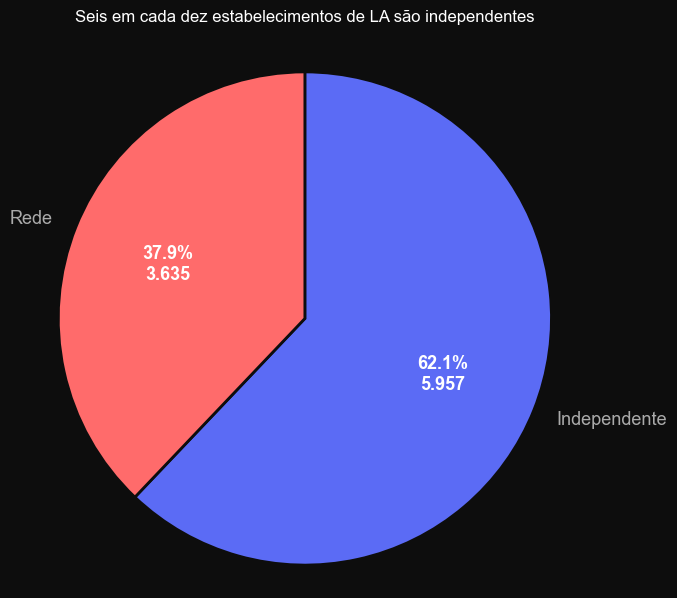

In [438]:
# Passo 2 — o gráfico. Aqui a pizza se defende: são 2 categorias, a soma fecha
# 100% de verdade, e os ângulos ficam em 223° contra 137° — diferença que o olho
# lê sem precisar de rótulo.

plt.figure(figsize=(7, 7))

total = redes['estabelecimentos'].sum()

def rotulo(pct):
    """autopct me dá só o percentual; recupero o absoluto a partir dele."""
    n = int(round(pct / 100 * total))
    return f'{pct:.1f}%\n{n:,}'.replace(',', '.')

wedges, textos, autotextos = plt.pie(
    redes['estabelecimentos'],
    labels=redes.index,
    autopct=rotulo,
    startangle=90,          # começa no topo
    counterclock=False,     # sentido horário: é como se lê um relógio
    colors=[CORES[0], CORES[1]],
    wedgeprops={'edgecolor': '#0d0d0d', 'linewidth': 2},   # separa as fatias
    textprops={'fontsize': 13},
)
plt.setp(autotextos, color='white', fontweight='bold', fontsize=13)
plt.axis('equal')           # sem isso a pizza pode sair oval

plt.title('Seis em cada dez estabelecimentos de LA são independentes', pad=20)
plt.savefig('images/2_2_rede_vs_independente.png')
plt.show()

**📝 Conclusão 2.2 — rede vs não-rede:**

**O mercado de LA é predominantemente de estabelecimentos independentes, mas não esmagadoramente.** São 5.957
estabelecimentos independentes (62,1%) contra 3.635 de rede (37,9%), em 9.592 no total.
Não é uma cidade de franquias, e também não é uma cidade onde rede seja raridade.

**A leitura que importa para os investidores.** A pergunta por trás desta seção é se o
modelo de rede é viável em LA. O número diz que sim: quase quatro em cada dez
estabelecimentos da cidade pertencem a alguma rede. Isso é volume suficiente para
descartar a hipótese de que virar rede seria nadar contra o mercado. Mas 37,9% também não
é o padrão: a maioria dos estabelecimentos de LA opera sozinha, o que significa que
independente é um modelo que se sustenta na cidade com certa comprovação dos 62,1% encontrados, e não um estágio provisório de quem ainda não cresceu.

**Escolha do gráfico:** duas categorias, soma fechando 100% e ângulos de 224° contra
136°. É o único caso do projeto em que a pizza é claramente defensável, e por isso
usei ela aqui e barra no 2.1. O critério é o mesmo nos dois: número de categorias, diferença de quantas categorias que foi influente na decisão.

**O que este número NÃO responde.** Ele é sobre a cidade inteira, todos os tipos
somados. Não diz se *cafés* tendem a ser rede: pode ser que redes se concentrem em
fast food e que café seja majoritariamente independente, ou o contrário. Os 37,9% são o
pano de fundo; o recorte por tipo é a pergunta do 2.3.

**Uma ressalva que vem do Passo 1.** A coluna `chain` é declarada na fonte, não derivada
dos dados, e eu já vi que ela não é perfeitamente consistente: no 1.3 apareceram
registros do mesmo estabelecimento com `chain` divergente entre as duas linhas. Os 37,9%
são a melhor estimativa que a base oferece, não uma contagem auditada.


### 2.3 Que tipo de estabelecimento é típico para redes

> **Enunciado:** Qual tipo de estabelecimento é típico para redes?

Agora cruzo as duas variáveis anteriores. Preciso ter cuidado aqui: "típico para redes" pode ser lido de duas
formas, e as duas dão respostas diferentes. Preciso escolher uma, dizer qual escolhi e por quê —
essa é exatamente a armadilha do Paradoxo de Simpson que já estudei.

In [439]:
# -----------------------------------------------------------------------------
# 2.3 Tipo de estabelecimento típico para redes
# -----------------------------------------------------------------------------
# A ambiguidade que preciso resolver ANTES de codar:
#   Leitura A — dentro das redes, qual tipo aparece mais? (base = só redes)
#   Leitura B — dentro de cada tipo, qual tem maior % de redes? (base = cada tipo)
# São perguntas diferentes. A leitura B é a que responde "esse tipo TENDE a ser
# rede", que é o que o investidor quer saber. Vou calcular as duas e mostrar a
# que responde a pergunta de negócio, comentando a diferença.

so_redes = rest[rest['chain']]
leitura_a = pd.DataFrame({
    'estabelecimentos': so_redes['object_type'].value_counts(),
    'proporcao_%': so_redes['object_type'].value_counts(normalize=True) * 100,
})
display(leitura_a)

# usarei: o observed=True — o groupby percorre só as categorias que de fato aparecem nos dados que temos
por_tipo = rest.groupby('object_type', observed=True)['chain'].agg(
    total='size',     # quantos estabelecimentos desse tipo existem
    redes='sum',      # quantos deles são rede
)
por_tipo['pct_rede'] = por_tipo['redes'] / por_tipo['total'] * 100
por_tipo = por_tipo.sort_values('pct_rede', ascending=False)
display(por_tipo)

,estabelecimentos,proporcao_%
object_type,,
Restaurant,2268,62.393398
Fast Food,601,16.533700
Bakery,283,7.785420
Cafe,258,7.097662
Pizza,148,4.071527
Bar,77,2.118294


,total,redes,pct_rede
object_type,,,
Bakery,283,283,100.000000
Cafe,426,258,60.563380
Fast Food,1060,601,56.698113
Pizza,314,148,47.133758
Restaurant,7217,2268,31.425800
Bar,292,77,26.369863


In [440]:
# Checagm extra dos dados porque temos 100% das padarias sendo rede

padarias = rest[rest['object_type'] == 'Bakery']
print(padarias['chain'].value_counts())
display(padarias[['object_name', 'marca', 'address', 'number']].head(15))
print('marcas distintas entre as padarias:', padarias['marca'].nunique())

chain
True    283
Name: count, dtype: int64


,object_name,marca,address,number
11,POONG NYUN BAKERY,POONG NYUN BAKERY,928 S WESTERN AVE STE 109,17
14,CUSCATLECA BAKERY,CUSCATLECA BAKERY,2501 W SUNSET BLVD #A,26
34,MUSH BAKERY,MUSH BAKERY,5224 W SUNSET BLVD,15
44,LA MONARCA BAKERY,LA MONARCA BAKERY,5835 N FIGUEROA ST,35
95,CELAYA BAKERY,CELAYA BAKERY,1630 W SUNSET BLVD,16
96,K-BAKERY,K BAKERY,1258 W TEMPLE ST,6
97,LOS PINITOS NUEVOS BAKERY,LOS PINITOS NUEVOS BAKERY,1154 S LORENA ST,4
114,DELICIAS BAKERY AND SOME,DELICIAS BAKERY SOME,5567 N FIGUEROA ST,5
176,LE BALCON BAKERY,LE BALCON BAKERY,1523 LA BREA AVE,2
186,OPERA HOUSE BAKERY,OPERA HOUSE BAKERY,833 S WESTERN AVE 38,23


marcas distintas entre as padarias: 249


In [441]:
# Quantas unidades tem a marca típica de cada tipo, entre as marcadas como rede?
# Rede de verdade = marca com VÁRIAS unidades. Se a mediana der 1, a flag `chain`
# não está descrevendo rede naquela categoria.

unidades = (rest[rest['chain']]
            .groupby(['object_type', 'marca'], observed=True).size()
            .rename('unidades')
            .reset_index())

perfil = unidades.groupby('object_type', observed=True)['unidades'].agg(
    marcas='size', media='mean', mediana='median', maximo='max'
).round(2)
display(perfil.sort_values('media', ascending=False))

,marcas,media,mediana,maximo
object_type,,,,
Cafe,57,4.53,1.0,119
Fast Food,157,3.83,1.0,122
Pizza,41,3.61,2.0,30
Restaurant,1479,1.53,1.0,48
Bar,61,1.26,1.0,4
Bakery,249,1.14,1.0,6


In [442]:
# Já que temos café a frente em média e é o nosso olhar atento do projeto, vamos analisar mais:
# Vejo as redes de café agora 

cafes_rede = rest[(rest['object_type'] == 'Cafe') & rest['chain']]
top = cafes_rede['marca'].value_counts()

print(cafes_rede['marca'].nunique(), 'marcas de café de rede', '\n')
print(top.head(8))
print('\ntop 3 concentram:', round(top.head(3).sum() / len(cafes_rede) * 100, 1), '% dos cafés de rede')
print('marcas com 1 unidade só:', (top == 1).sum(), 'de', len(top))

57 marcas de café de rede 

marca
STARBUCKS                    119
COFFEE BEAN TEA LEAF          55
BLUE BOTTLE COFFEE             9
TOM N TOMS COFFEE              5
PEETS COFFEE TEA               4
TIERRA MIA COFFEE COMPANY      3
COFFEE COMMISSARY              3
GROUNDWORK COFFEE              2
Name: count, dtype: int64

top 3 concentram: 70.9 % dos cafés de rede
marcas com 1 unidade só: 40 de 57


In [443]:
# teste anterior que ocasionou correções na parte 1 do projeto, agora está correto
base = rest['marca'].str.replace(r'^THE ', '', regex=True).str.replace(r'\bAND\b', '', regex=True)
base = base.str.replace(r'\s+', ' ', regex=True).str.strip()
colisoes = pd.DataFrame({'marca': rest['marca'], 'base': base}).drop_duplicates()
colisoes = colisoes.groupby('base')['marca'].apply(list)
display(colisoes[colisoes.str.len() > 1])

Series([], Name: marca, dtype: object)

**📝 Conclusão 2.3 — tipo típico das redes:**

**A leitura que escolhi: B, dentro de cada tipo.** As duas respondem perguntas diferentes.
A leitura A pergunta "dos estabelecimentos de rede, quantos são de cada tipo?", e a
resposta é dominada pelo tamanho da categoria, não pelo comportamento dela. A leitura B
pergunta "de todos os cafés, quantos são rede?", que é a pergunta condicionada ao tipo, e
é a que responde se o formato escala. Como eu vou decidir sobre um formato específico,
é a B que importa. Calculei as duas assim mesmo, porque a comparação é reveladora.

**E elas discordam por completo:**

| | leitura A (dentro das redes) | leitura B (dentro do tipo) |
|---|---|---|
| 1º | Restaurant 2.268, 62,4% | Bakery 100,0% |
| 2º | Fast Food 601, 16,5% | Cafe 60,6% |
| 3º | Bakery 283, 7,8% | Fast Food 56,7% |
| … | Cafe 258, 7,1% | Restaurant 31,4% |

Restaurant lidera a leitura A com 62,4% e é o **penúltimo** na leitura B, com 31,4%:
lidera por ser 75% da cidade, não por tender a virar rede. É o caso concreto de "a base
muda a resposta" que eu tinha antecipado: os mesmos dados, duas perguntas, respostas
opostas. Se eu tivesse calculado só uma, teria concluído com confiança a coisa errada, por isso a análise por tipo mais a fundo com intenção de revelar um direcionamento sobre os cafés.

**O primeiro lugar da leitura B é artefato, e eu descarto.** As 283 padarias estão
marcadas como rede: todas, sem uma exceção. Fui verificar: são **249 marcas distintas**,
média de 1,14 unidade por marca, e a maior "rede" de padarias de LA tem **6 unidades**.
Rede é uma marca com várias unidades; 249 marcas para 283 endereços é o oposto disso. O
`chain` foi preenchido com outro critério nessa categoria, coerente com o que registrei
no Passo 1, de que a flag é declarada na fonte e não derivada dos dados.

Importante: descartei pela implausibilidade, não pelo resultado. E a medida abaixo, que
usa outro critério, coloca Bakery em último por conta própria; não dependeu do meu
julgamento.

**Uma terceira medida, que é a que fecha as análises desse passo:** "% marcado como rede" mede o que a
fonte declarou. Quantas unidades cada marca tem mede o que a rede realmente é:

| tipo | marcas | unidades/marca (média) | maior rede |
|---|---|---|---|
| **Cafe** | 57 | **4,53** | 119 |
| Fast Food | 157 | 3,83 | 122 |
| Pizza | 41 | 3,61 | 30 |
| Restaurant | 1.479 | 1,53 | 48 |
| Bar | 61 | 1,26 | 4 |
| Bakery | 249 | 1,14 | 6 |

Bar e Bakery caem para o fim: a maior "rede" deles tem 4 e 6 unidades. Não são redes
pequenas, são categorias onde a flag não descreve rede. E **café aparece em primeiro**,
por duas medidas independentes: 60,6% de rede e a maior replicação por marca.

**Onde a cafeteria se posiciona: no formato que mais vira rede em LA.** Seis em cada dez
cafés pertencem a alguma rede, contra 37,9% da cidade inteira. É a resposta favorável à
pergunta que os investidores fizeram: o formato escala neste mercado.

**Mas o formato de escala tem uma cara específica, e ela importa mais que o percentual.**
São 258 cafés de rede distribuídos em 57 marcas, e a distribuição é brutalmente desigual:

+ STARBUCKS               119
+ COFFEE BEAN TEA LEAF     55   ->  duas marcas = 67,4% de tudo

Em relação ao restante temos: 40 das 57 marcas com apenas UMA unidade, 
Não existe camada intermediária. O mercado de café de rede em LA é dois gigantes e uma
cauda de marcas com uma loja: o espaço entre 1 e 119 unidades está praticamente vazio.
Então "café escala" é verdade, mas o caminho observável na cidade não é crescer devagar
até virar rede média: é permanecer com uma unidade ou planejar ser um Starbucks.

**Duas ressalvas.** A mediana de unidades por marca é 1,0 em quase todos os tipos,
inclusive café: a média de 4,53 é puxada pelas duas gigantes. E, como registrei no Passo
1, `chain` é declarado na fonte: uma marca com uma unidade em LA pode ser rede nacional
com lojas em outros estados. A mediana mede presença na cidade, não tamanho da rede.


### 2.4 O que caracteriza uma rede

> **Enunciado:** O que caracteriza redes: muitos estabelecimentos com um pequeno número de assentos
> ou poucos estabelecimentos com muitos assentos?

Essa é uma pergunta de **duas dimensões ao mesmo tempo**: número de unidades por marca × assentos
por unidade. Não dá pra responder com um número só, e é a pergunta que mais diretamente informa a
estratégia do meu próprio negócio.

In [444]:
# -----------------------------------------------------------------------------
# 2.4 O que caracteriza uma rede: muitas unidades pequenas ou poucas grandes?
# -----------------------------------------------------------------------------
# A unidade de análise MUDA aqui. Até agora eu contava estabelecimentos; agora
# conto por MARCA, porque uma rede é uma marca com N unidades. Se eu continuasse
# contando linha, responderia outra pergunta.

redes = rest[rest['chain']]

por_marca = redes.groupby('marca', observed=True).agg(
    unidades=('id', 'size'),
    assentos_medio=('number', 'mean'),
    assentos_mediana=('number', 'median'),
)
print('marcas de rede:', len(por_marca), '| estabelecimentos de rede:', len(redes))

# --- Dimensão 1: quantas unidades tem uma rede? ------------------------------
print('\nUnidades por marca:')
print(por_marca['unidades'].describe().round(2))
# describe() dá o resumo, não a forma. Quero saber quantas marcas há de cada
# tamanho, porque é a forma que responde "muitas ou poucas".


marcas de rede: 2041 | estabelecimentos de rede: 3635

Unidades por marca:
count    2041.00
mean        1.78
std         4.94
min         1.00
25%         1.00
50%         1.00
75%         1.00
max       122.00
Name: unidades, dtype: float64


In [445]:
# Verificando unidades por marca, para ver a distribuição de quantas marcas têm 1, 2, 3, ... unidades.
dist = por_marca['unidades'].value_counts().sort_index()
dist.index.name = 'unidades_por_marca'
dist.name = 'quantas_marcas'
print(dist.head(8))
print('máximo:', por_marca['unidades'].max())

# --- Dimensão 2: rede tem mais ou menos assentos que independente? -----------
# Aqui a unidade volta a ser o estabelecimento: a pergunta é sobre o tamanho de
# cada ponto, não da marca.
print('\nAssentos por estabelecimento:')
print(rest.groupby('chain')['number'].agg(['count', 'mean', 'median']).round(1))

unidades_por_marca
1    1541
2     335
3      69
4      32
5      17
6       7
7       5
8       2
Name: quantas_marcas, dtype: int64
máximo: 122

Assentos por estabelecimento:
       count  mean  median
chain                     
False   5957  46.2    28.0
True    3635  39.8    25.0


In [446]:
# As duas dimensões medidas separadamente não respondem o enunciado. A pergunta
# é sobre a RELAÇÃO entre elas: quem tem mais unidades opera com menos assentos?

# --- Concentração: quanto do mercado de rede está nas marcas grandes? --------
grandes = por_marca['unidades'] >= 5
print('marcas com 5+ unidades: %d (%.1f%% das marcas)' % (grandes.sum(), grandes.mean() * 100))
print('  e elas somam %d estabelecimentos (%.1f%% das redes)'
    % (por_marca.loc[grandes, 'unidades'].sum(),
         por_marca.loc[grandes, 'unidades'].sum() / len(redes) * 100))

# --- A relação, por correlação ----------------------------------------------
# Pearson mede relação linear e sofre com o outlier de 122 unidades. Spearman
# trabalha com a ordem, não com o valor, e aguenta cauda longa. Vejo as duas.
print('\ncorrelação unidades x assentos médios:')
print('  Pearson : %.3f' % por_marca['unidades'].corr(por_marca['assentos_medio']))
print('  Spearman: %.3f' % por_marca['unidades'].corr(por_marca['assentos_medio'],
                                                    method='spearman'))

# --- A mesma relação, por faixa de tamanho ----------------------------------
# Correlação resume em um número e pode esconder padrão não-linear. Agrupar em
# faixas mostra a trajetória: os assentos caem conforme a rede cresce?
faixas = pd.cut(por_marca['unidades'], [0, 1, 2, 4, 9, 1000],
                labels=['1', '2', '3-4', '5-9', '10+'])
print('\nassentos por faixa de tamanho da rede:')
print(por_marca.groupby(faixas, observed=True).agg(
    marcas=('unidades', 'size'),
    assentos_medio=('assentos_medio', 'mean'),
    assentos_mediana=('assentos_mediana', 'median')).round(1))

# --- Quem são as maiores ----------------------------------------------------
print('\nas 10 maiores redes:')
print(por_marca.nlargest(10, 'unidades').round(1))


marcas com 5+ unidades: 64 (3.1% das marcas)
  e elas somam 1089 estabelecimentos (30.0% das redes)

correlação unidades x assentos médios:
  Pearson : -0.001
  Spearman: 0.019

assentos por faixa de tamanho da rede:
          marcas  assentos_medio  assentos_mediana
unidades                                          
1           1541            40.3              25.0
2            335            39.0              23.5
3-4          101            37.0              23.5
5-9           35            42.2              23.0
10+           29            35.7              24.0

as 10 maiores redes:
                      unidades  assentos_medio  assentos_mediana
marca                                                           
SUBWAY                     122            17.1              16.0
STARBUCKS                  119            27.2              25.0
MCDONALDS                   80            92.6              92.0
COFFEE BEAN TEA LEAF        55            24.7              22.0
JACK IN THE BO

In [447]:
# O nicho, isolado: só cafés E só de rede. Cada condição entre parênteses,
# porque o `&` do pandas tem precedência maior que o `==` e sem os parênteses
# a expressão é avaliada na ordem errada, faço isso para mostrar o nicho desejado
cafes_rede = rest[(rest['object_type'] == 'Cafe') & rest['chain']]

top5_cafes = (cafes_rede.groupby('marca', observed=True)
            .agg(unidades=('id', 'size'),
                assentos_medio=('number', 'mean'),
                assentos_mediana=('number', 'median'))
            .nlargest(5, 'unidades')
            .round(1))
display(top5_cafes)

print('cafés de rede: %d em %d marcas' % (len(cafes_rede), cafes_rede['marca'].nunique()))
print('as 5 acima concentram: %.1f%% do segmento'
      % (top5_cafes['unidades'].sum() / len(cafes_rede) * 100))


,unidades,assentos_medio,assentos_mediana
marca,,,
STARBUCKS,119,27.2,25.0
COFFEE BEAN TEA LEAF,55,24.7,22.0
BLUE BOTTLE COFFEE,9,21.9,27.0
TOM N TOMS COFFEE,5,69.2,78.0
PEETS COFFEE TEA,4,22.5,21.5


cafés de rede: 258 em 57 marcas
as 5 acima concentram: 74.4% do segmento


In [448]:
# Temos um padrão mais ou menos desenhado para esses cafés de rede, importante notar a média e mediana de assentos
# Apenas a tom n toms distoa nos nos dados, de resto está entre 21 e 27 assentos.
# Plotagem dos gráficos:

# --- 2.4 gráfico: a relação entre as duas dimensões --------------------------
# Corto em 5 unidades e digo por quê: a pergunta é sobre marcas que operam COMO
# rede. Com as 2.041, três quartos ficam empilhados em x=1 e viram uma parede que
# esconde justamente a relação que eu quero enxergar. A distribuição completa já
# está respondida na tabela acima; aqui olho quem replicou.
#
# Plotly em vez de seaborn porque são 64 marcas: rótulo estático para todas seria
# ilegível, e o hover resolve sem poluir. É o caso em que a interatividade agrega de verdade

perfil_redes = redes.groupby('marca', observed=True).agg(
    unidades=('id', 'size'),
    assentos_mediana=('number', 'median'),
    assentos_medio=('number', 'mean'),
    tipo=('object_type', lambda s: s.value_counts().idxmax()),
).reset_index()

CORTE = 5
reais = perfil_redes[perfil_redes['unidades'] >= CORTE].copy()
reais['assentos_medio'] = reais['assentos_medio'].round(1)
print(f'marcas com {CORTE}+ unidades: {len(reais)} de {len(perfil_redes)}')

fig = px.scatter(
    reais, x='unidades', y='assentos_mediana',
    color='tipo',
    log_x=True,                # 5 a 122 numa escala só; sem log, tudo à esquerda
    size='unidades', size_max=26,
    hover_name='marca',
    hover_data={'unidades': True, 'assentos_mediana': True,
                'assentos_medio': True, 'tipo': False},
    labels={'unidades': 'unidades da marca em LA',
            'assentos_mediana': 'assentos por unidade (mediana)',
            'assentos_medio': 'assentos (média)', 'tipo': 'tipo'},
    color_discrete_sequence=CORES,
    template=TEMPLATE_PLOTLY,
)

# A linha de referência é o que torna o achado visível: se houvesse relação, a
# nuvem desceria ou subiria conforme anda para a direita. Ela não faz nem um nem outro.
mediana_rede = redes['number'].median()
fig.add_hline(y=mediana_rede, line_dash='dash', line_color='#888888',
            annotation_text=f'mediana das redes: {mediana_rede:.0f} assentos',
            annotation_position='top left')

fig.update_xaxes(tickvals=[5, 10, 20, 50, 100], ticktext=['5', '10', '20', '50', '100'])
fig.update_layout(title='Tamanho da rede não determina tamanho da loja', height=560,
                paper_bgcolor='#0d0d0d', plot_bgcolor='#0d0d0d')

# O PNG é para a apresentação; o fig.show() é para explorar aqui.
fig.write_image('images/2_4_redes_unidades_vs_assentos.png', width=1100, height=560, scale=2)
fig.show()


marcas com 5+ unidades: 64 de 2041


**📝 Conclusão 2.4 — o que caracteriza uma rede:**


**A resposta direta ao enunciado: nenhuma das duas.** As duas opções oferecidas supõem
que o tamanho da rede e o tamanho da loja andam juntos. Não andam. Redes se caracterizam
por ter muitas unidades, sim, mas quantos assentos cada unidade tem é uma decisão
separada, que não acompanha o crescimento da rede em direção nenhuma.

**Dimensão 1: a rede típica tem uma unidade.** São 2.041 marcas de rede para 3.635
estabelecimentos. A mediana é 1 unidade, e o terceiro quartil também: 1.541 marcas
(75,5%) aparecem uma única vez na base. A média de 1,78 e o desvio-padrão de 4,94 contam
a mesma história por outro ângulo, com o desvio quase três vezes maior que a média.

A distribuição é cauda longa clássica. Na outra ponta, 64 marcas (3,1% do total) têm 5 ou
mais unidades e sozinhas respondem por 1.089 estabelecimentos, 30% de todo o mercado de
rede. "Rede típica" e "rede grande" são objetos diferentes, e falar de uma como se fosse
a outra seria erro grosseiro.

**Dimensão 2: redes operam com lojas menores.** Mediana de 25 assentos contra 28 dos
independentes; média de 39,8 contra 46,2. As duas medidas concordam na direção, o que dá
confiança de que não é efeito de outlier. Mas a magnitude é modesta: 3 assentos de
diferença na mediana. É um achado real e pequeno, e apresentá-lo como se fosse grande
seria vender mais do que o dado entrega.

**A relação entre as duas: não existe.** Testei de três formas:

| teste | resultado |
|---|---|
| correlação de Pearson | -0,001 |
| correlação de Spearman | 0,019 |
| assentos medianos por faixa de tamanho | 25,0 / 23,5 / 23,5 / 23,0 / 24,0 |

A faixa vai de marcas com 1 unidade até marcas com 10 ou mais, e a mediana de assentos
oscila entre 23 e 25 o caminho inteiro. Usei as duas correlações porque a distribuição de
unidades é muito assimétrica: o Pearson sofre com a Subway de 122 unidades puxando o
resultado, e o Spearman, que trabalha com posições em vez de valores, não sofre. As duas
dando zero é mais convincente que uma sozinha.

Uma limitação técnica que preciso registrar: correlação perde poder quando há muitos
empates, e aqui 1.541 das 2.041 marcas têm exatamente o mesmo valor de unidades. Para três
quartos da base a variável não varia. Por isso a tabela por faixa vale mais que os
coeficientes: ela mostra a trajetória em vez de resumir tudo num número.

**Por que o resultado deu zero: existem duas famílias de rede.** O gráfico de dispersão
mostra o que a correlação esconde. Entre as maiores:

| formato pequeno | un. | assentos | formato grande | un. | assentos |
|---|---:|---:|---|---:|---:|
| Domino's Pizza | 30 | 12 | Taco Bell | 29 | 34 |
| Pizza Hut | 29 | 14 | Jack in the Box | 48 | 44 |
| Subway | 122 | 16 | El Pollo Loco | 36 | 48 |
| Coffee Bean | 55 | 22 | Burger King | 38 | 82 |
| Starbucks | 119 | 25 | McDonald's | 80 | 92 |


As duas escalam igual. A Subway chega a 122 unidades com 16 assentos; o McDonald's chega
a 80 com 92. Uma família puxa a correlação para baixo, a outra para cima, e o resultado se
anula. Não é ausência de padrão, são dois padrões que se cancelam.

**E o tipo de estabelecimento não explica a diferença.** Foi a primeira hipótese que
testei, e ela falhou. Dentro de `Fast Food` convivem Subway com 16 assentos e McDonald's
com 92; dentro de `Restaurant`, Jamba Juice com 19 e Carl's Jr com 103. Entre as redes
grandes, a mediana por tipo é quase plana: Pizza 14, Fast Food 21,5, Bakery e Restaurant
24,5, Cafe 26. Só pizza destoa, e por razão evidente, já que o modelo é entrega. O tamanho
da loja é decisão de marca, não consequência da categoria.

**Recorte do gráfico:** cortei em 5 unidades para desenhar a dispersão. Com as 2.041
marcas, três quartos ficam empilhados numa linha vertical em x=1 e escondem a relação que
o gráfico existe para mostrar. A distribuição completa está na tabela acima; o gráfico
responde a outra pergunta, sobre marcas que de fato operam como rede.

**O que isso diz sobre a cafeteria.** As duas maiores redes de café de LA operam com 25
(Starbucks) e 22 (Coffee Bean) assentos medianos. Elas provam que é possível chegar a 119
e 55 unidades nessa faixa de tamanho: o formato pequeno não é limitação para escalar. Se
a decisão for crescer em número de pontos, o dado diz que isso não exige loja grande, e
sugere o contrário.

**Ressalvas.**

- As correlações são descritivas. Mesmo se tivessem dado diferente de zero, descreveriam o
  padrão do mercado de LA, não provariam que uma coisa causa a outra.
- "Uma unidade em LA" não é o mesmo que "não é rede". Como registrei no Passo 1, `chain` é
  declarado na fonte: uma marca com uma loja na cidade pode ser rede nacional. A mediana de
  1 unidade mede presença em LA, não tamanho da rede.
- As duas famílias de formato que descrevi acima aparecem entre as marcas com 5 ou mais
  unidades, que são as únicas do gráfico. Não testei se esse padrão existe na cidade
  inteira, então não afirmo que LA tenha dois tamanhos típicos de estabelecimento. O que
  observei vale para quem escalou, e é dessas marcas que a pergunta do enunciado trata.


### 2.5 Número médio de assentos por tipo

> **Enunciado:** Determine o número médio de assentos para cada tipo de restaurante. Em média, qual
> tipo de restaurante tem o maior número de assentos? Construa gráficos.

O enunciado pede média — mas média é frágil a outlier, e no 1.5 eu já vou ter visto se `number` tem
valores extremos. Vou entregar a média que ele pediu **e** a mediana ao lado, com o motivo.

In [449]:
# -----------------------------------------------------------------------------
# 2.5 Número médio de assentos por tipo de estabelecimento
# -----------------------------------------------------------------------------
# Queremos a média. Entregarei ambas: média E mediana, porque já sei do Passo 1 que
# `number` é assimétrico à direita: metade dos estabelecimentos tem 27 assentos
# ou menos, mas a cauda vai até 229. Média sozinha descreveria um lugar que quase
# não existe, e é sobre esse número que vou recomendar tamanho ao investidor.

assentos_por_tipo = (rest.groupby('object_type', observed=True)['number']
                    .agg(n='count', media='mean', mediana='median', desvio='std',
                        p25=lambda s: s.quantile(.25),
                        p75=lambda s: s.quantile(.75))
                    .round(1)
                    .sort_values('media', ascending=False))

# A divergência entre média e mediana, medida em vez de olhada no olho. Quanto
# maior o percentual, mais a média está sendo puxada pela cauda daquele tipo.
assentos_por_tipo['media_acima_da_mediana_%'] = (
    (assentos_por_tipo['media'] / assentos_por_tipo['mediana'] - 1) * 100).round(0)

# Coeficiente de variação: desvio dividido pela média. O desvio sozinho não
# compara categorias de tamanhos diferentes, porque 21,4 de desvio significa uma
# coisa numa média de 24,9 e outra bem diferente numa média de 48,1. Dividir pela
# média põe todas na mesma escala. Abaixo de 1 quer dizer que os estabelecimentos
# daquele tipo variam MENOS que o próprio tamanho típico deles.
# Calculo a partir do `rest`, e não da tabela acima, porque ela já foi arredondada:
# dividir números arredondados empurraria o Bar de 1,05 para 1,04.
cv = (rest.groupby('object_type', observed=True)['number'].std() /
    rest.groupby('object_type', observed=True)['number'].mean())
assentos_por_tipo['coef_variacao'] = cv.round(2)

display(assentos_por_tipo)

# A pergunta literal do enunciado: qual tipo tem o maior número médio?
print('maior média :', assentos_por_tipo.index[0],
    '(%.1f assentos)' % assentos_por_tipo['media'].iloc[0])

# E a pergunta que o enunciado não faz, mas que eu preciso responder antes de
# escolher uma das duas medidas: a ordem depende de qual delas eu usar?
# usarei tolist()
print('\nordem pela média  :', assentos_por_tipo.index.tolist())
print('ordem pela mediana:',
    assentos_por_tipo['mediana'].sort_values(ascending=False).index.tolist())

print('\ndispersão relativa (menor = mais previsível):')
print(cv.sort_values().round(2).to_string())
print('\ncategorias com dispersão MENOR que a própria média:',
    cv[cv < 1].round(2).to_dict())


,n,media,mediana,desvio,p25,p75,media_acima_da_mediana_%,coef_variacao
object_type,,,,,,,,
Restaurant,7217,48.1,29.0,50.6,15.0,49.0,66.0,1.05
Bar,292,44.8,28.5,46.8,13.0,48.0,57.0,1.05
Fast Food,1060,31.9,21.0,35.2,11.0,37.0,52.0,1.10
Pizza,314,28.7,19.0,35.7,9.2,29.0,51.0,1.24
Cafe,426,24.9,20.0,21.4,11.0,33.8,24.0,0.86
Bakery,283,21.8,18.0,25.7,9.0,24.0,21.0,1.18


maior média : Restaurant (48.1 assentos)

ordem pela média  : ['Restaurant', 'Bar', 'Fast Food', 'Pizza', 'Cafe', 'Bakery']
ordem pela mediana: ['Restaurant', 'Bar', 'Fast Food', 'Cafe', 'Pizza', 'Bakery']

dispersão relativa (menor = mais previsível):
object_type
Cafe          0.86
Bar           1.05
Restaurant    1.05
Fast Food     1.10
Bakery        1.18
Pizza         1.24

categorias com dispersão MENOR que a própria média: {'Cafe': 0.86}


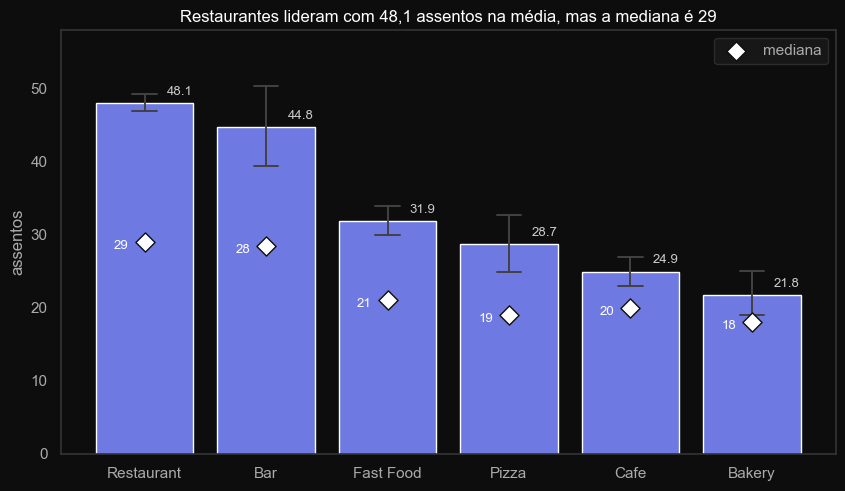

In [450]:
# --- Gráfico 1: a pergunta literal do enunciado ------------------------------
# A barra é a MÉDIA, que é o que o enunciado pede. O losango branco é a mediana,
# no mesmo eixo: a distância entre os dois é a assimetria daquele tipo, visível
# sem precisar de tabela. Entrego as duas medidas num gráfico só.
# A barrinha vertical é o intervalo de confiança de 95%, que o seaborn calcula
# por bootstrap. Ela não é enfeite: a de Bar (n=292) é muito mais longa que a de
# Restaurant (n=7.217), e as duas quase se tocam, o que significa que a diferença
# entre 48,1 e 44,8 não é uma afirmação segura.

tab = (rest.groupby('object_type', observed=True)['number']
       .agg(media='mean', mediana='median').sort_values('media', ascending=False))
ordem = tab.index.tolist()

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=rest, x='object_type', y='number', order=ordem,
              color=CORES[0], errorbar=('ci', 95), capsize=.2,
              err_kws={'linewidth': 1.4})

ax.scatter(range(len(ordem)), tab['mediana'], color='white', s=95, zorder=5,
       marker='D', edgecolors='#0d0d0d', linewidths=1, label='mediana')

for i, tp in enumerate(ordem):
    ax.annotate(f"{tab.loc[tp, 'media']:.1f}", (i, tab.loc[tp, 'media']),
              xytext=(16, 6), textcoords='offset points', fontsize=9.5, color='#cccccc')
    ax.annotate(f"{tab.loc[tp, 'mediana']:.0f}", (i, tab.loc[tp, 'mediana']),
              xytext=(-22, -5), textcoords='offset points', fontsize=9.5, color='white')

ax.set_ylim(0, 58)          # espaço para o rótulo da barra mais alta
ax.set_xlabel(''); ax.set_ylabel('assentos')
ax.grid(axis='y'); ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
ax.set_title('Restaurantes lideram com 48,1 assentos na média, mas a mediana é 29')
plt.savefig('images/2_5_assentos_por_tipo.png')
plt.show()


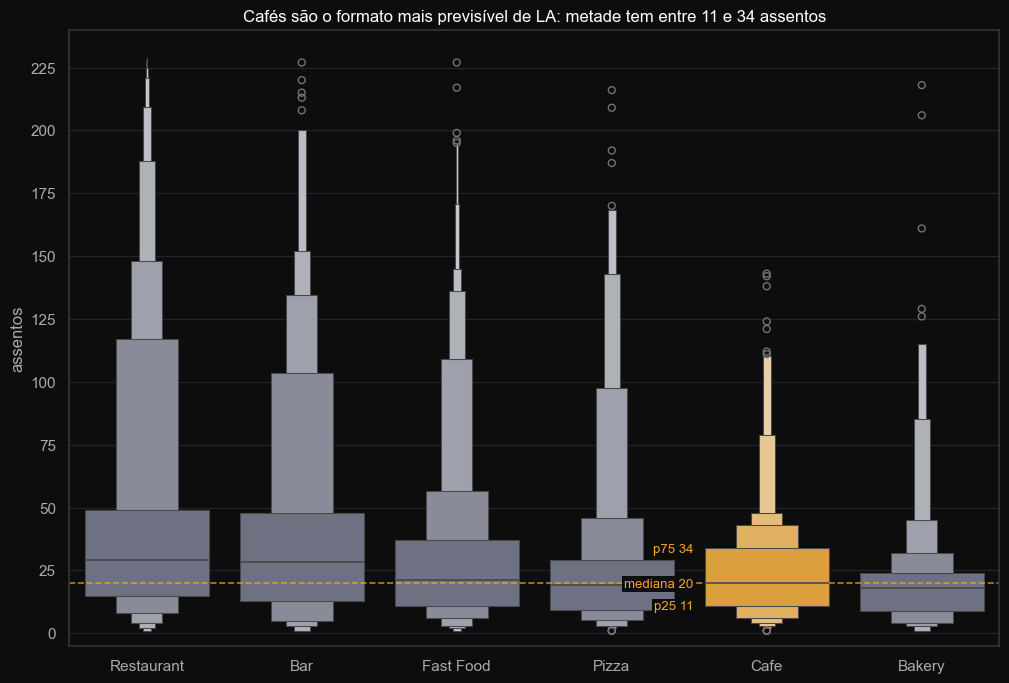

In [451]:
# --- Gráfico 2: a forma, que o resumo esconde --------------------------------
# Escolhi boxenplot em vez de boxplot ou violino por causa do tamanho e da forma
# da amostra. O violino suaviza a curva, o que apaga a estrutura da cauda quando
# há 7.217 observações como em Restaurant. O boxplot joga tudo acima do bigode
# numa nuvem de pontos: em Fast Food e Pizza são tantos que a nuvem vira uma
# linha contínua sem informação.
#
# COMO LER: a caixa mais larga do meio é a metade central dos dados, do percentil
# 25 ao 75, com a linha na mediana. Cada faixa mais estreita acima cobre metade do
# que sobrou. Regra prática: a LARGURA diz quantos, a ALTURA diz até onde. Se a
# pirâmide continua larga lá em cima, muitos estabelecimentos são grandes; se
# afina rápido, os grandes são exceção.
#
# Destaco Cafe porque é a categoria do projeto, e o gráfico mostra justamente que
# ela é a mais compacta das seis.

CINZA = '#6b6f85'
DESTAQUE = CORES[2]                     # âmbar
paleta = [DESTAQUE if t == 'Cafe' else CINZA for t in ordem]

cafe = rest.loc[rest['object_type'] == 'Cafe', 'number']
p25, med, p75 = cafe.quantile(.25), cafe.median(), cafe.quantile(.75)
i_cafe = ordem.index('Cafe')

plt.figure(figsize=(12, 8))
ax = sns.boxenplot(data=rest, x='object_type', y='number', order=ordem,
                hue='object_type', hue_order=ordem, legend=False,
                palette=paleta, width=.8, line_kws={'linewidth': 1.2})

# Escala de 25 em 25, com grade em cada marca. De 50 em 50 obrigava o leitor a
# interpolar no olho para achar onde cada caixa termina.
ax.set_yticks(range(0, 251, 25))
ax.set_ylim(-5, 240)
ax.grid(axis='y', color='#242430', linewidth=.9)
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)

# Referência horizontal na mediana dos cafés, atravessando todas as categorias:
# vira régua para comparar as outras contra a nossa.
ax.axhline(med, color=DESTAQUE, ls='--', lw=1.2, alpha=.75, zorder=1)

# Os três números da caixa âmbar, rotulados à ESQUERDA dela: à direita ficariam
# colados na coluna seguinte. A cor amarra os rótulos ao tracejado, então a linha
# não precisa de legenda própria.
for val, rot in [(p25, f'p25 {p25:.0f}'),
                (med, f'mediana {med:.0f}'),
                (p75, f'p75 {p75:.0f}')]:
    ax.annotate(rot, xy=(i_cafe - .42, val), xytext=(-6, -3),
                textcoords='offset points', fontsize=9.5, color=DESTAQUE, ha='right',
                zorder=6,
                bbox=dict(facecolor='#0d0d0d', edgecolor='none', pad=1.6))


ax.set_xlabel('')
ax.set_ylabel('assentos')
ax.set_title('Cafés são o formato mais previsível de LA: metade tem entre 11 e 34 assentos')
plt.savefig('images/2_5_distribuicao_assentos_por_tipo.png')
plt.show()


In [452]:
# O intervalo que o gráfico desenha, em número. Uso a aproximação normal
# (média ± 1,96 × erro padrão); o seaborn desenha por bootstrap, então os
# limites podem diferir na primeira casa decimal.
# Ic95 está ligado ao índice de confiança de 95%: 
# se eu repetisse a coleta 100 vezes, em 95 delas a média cairia nesse intervalo.
ic = (rest.groupby('object_type', observed=True)['number']
    .agg(media='mean', desvio='std', n='count'))
ic['ic95_de'] = ic['media'] - 1.96 * ic['desvio'] / ic['n'] ** .5
ic['ic95_ate'] = ic['media'] + 1.96 * ic['desvio'] / ic['n'] ** .5
display(ic[['n', 'media', 'ic95_de', 'ic95_ate']].round(1))

# Quanto de cada tipo é estabelecimento grande. Sustenta a leitura da cauda no boxenplot.
print('\n% com 100 assentos ou mais:')
print(rest.assign(grande=rest['number'] >= 100)
    .groupby('object_type', observed=True)['grande'].mean().mul(100).round(1)
    .sort_values(ascending=False).to_string())


,n,media,ic95_de,ic95_ate
object_type,,,,
Bakery,283,21.8,18.8,24.8
Bar,292,44.8,39.4,50.1
Cafe,426,24.9,22.9,27.0
Fast Food,1060,31.9,29.8,34.0
Pizza,314,28.7,24.8,32.7
Restaurant,7217,48.1,46.9,49.2



% com 100 assentos ou mais:
object_type
Restaurant    16.3
Bar           14.4
Fast Food      7.7
Pizza          6.4
Cafe           2.3
Bakery         1.8


**📝 Conclusão 2.5 — assentos por tipo:**

**A resposta literal: `Restaurant` tem o maior número médio, com 48,1 assentos**, seguido
de `Bar` com 44,8. Na outra ponta, `Bakery` com 21,8. Mas essa resposta pede três
qualificações, e elas mudam bastante o que dá para fazer com o número.

**Primeira: em todos os seis tipos a média fica acima da mediana.** A cauda puxa o
resultado em toda categoria, e a distância varia muito:

| tipo | média | mediana | média acima da mediana |
|---|---:|---:|---:|
| Restaurant | 48,1 | 29,0 | +66% |
| Bar | 44,8 | 28,5 | +57% |
| Fast Food | 31,9 | 21,0 | +52% |
| Pizza | 28,7 | 19,0 | +51% |
| Cafe | 24,9 | 20,0 | +24% |
| Bakery | 21,8 | 18,0 | +21% |

Onde a divergência é grande, a média descreve um estabelecimento que quase não existe. O
restaurante mediano de LA tem 29 assentos, não 48.

**Segunda: a diferença entre os dois primeiros não é segura.** No gráfico das médias, a
barra de erro do `Bar` é visivelmente mais longa que a do `Restaurant`, porque `Bar` tem
292 observações contra 7.217. As duas faixas se sobrepõem, então afirmar que restaurantes
têm mais assentos que bares seria ler precisão que o dado não tem. Já a distância de
`Restaurant` para `Fast Food` é grande o bastante para as faixas nem se aproximarem.

**Terceira, e foi o que mais me chamou atenção: `Restaurant` e `Bar` não são parecidos só
na média.** A metade central das duas categorias é quase a mesma, 15 a 49 assentos em
`Restaurant` e 13 a 48 em `Bar`. Dois tipos de negócio completamente diferentes operando
na mesma faixa de tamanho.

**O que o boxenplot mostra e o resumo esconde.** As duas categorias líderes têm cauda larga
e comprida: a pirâmide continua grossa bem acima de 100 assentos, o que significa que
estabelecimento grande não é exceção ali, é uma parcela relevante do grupo. Dentro de um
mesmo rótulo convivem operações de tamanhos muito diferentes.

Registro uma hipótese para essa heterogeneidade, e como hipótese porque a base não permite
testar: `Restaurant` e `Bar` funcionam como categorias guarda-chuva, agrupando formatos de
negócio distintos sob o mesmo nome. Não existe campo de subtipo para verificar isso.

**Onde a cafeteria cai.** `Cafe` é o quinto em média (24,9) e o quarto em mediana (20,0). A
troca de posição com `Pizza` acontece porque pizza tem cauda mais longa: o estabelecimento
típico de pizza é menor (19 contra 20), mas algumas pizzarias grandes levantam a média dela
acima da de café. A troca ilustra por que as duas medidas importam. Não a uso como
conclusão, porque as faixas de erro das duas se sobrepõem no gráfico.

**E o achado que mais serve à decisão: café é o formato mais previsível dos seis.**
Dividindo o desvio-padrão pela média de cada tipo, para poder comparar categorias de
tamanhos diferentes na mesma escala:

+ Cafe:        0,86
+ Bar:       1,05
+ Restaurant:    1,05
+ Fast Food:     1,10
+ Bakery:        1,18
+ Pizza:         1,24


`Cafe` é a **única categoria em que a dispersão é menor que a própria média**. Nas outras
cinco, os estabelecimentos variam mais do que o tamanho típico deles. Na prática,
cafeterias em LA se parecem umas com as outras, e as demais categorias não.

Isso é vantagem para quem vai dimensionar uma: existe um padrão de fato, e não uma média
calculada em cima de coisas incomparáveis. Repare também que a ordem por dispersão não é a
ordem por tamanho. `Pizza` é a penúltima em média e a mais irregular de todas; `Bar` é a
segunda maior e a segunda mais previsível. Tamanho e regularidade são dimensões
independentes, o mesmo tipo de separação que o 2.4 encontrou entre número de unidades e
assentos.

**Primeira aproximação da recomendação.** Metade dos cafés de LA opera entre 11 e 34
assentos, com mediana de 20. Essa é a faixa do mercado. Ainda não é a recomendação final:
falta cruzar com o que o 2.4 mostrou sobre as redes de café que escalaram, Starbucks com
mediana de 25 e Coffee Bean com 22, e com o recorte por localização dos passos 2.7 a 2.9.



### 2.6 Extração do nome da rua

> **Enunciado:** Coloque os dados dos nomes das ruas da coluna `address` em uma coluna separada.

Esta é a única etapa de **engenharia de dados** do projeto, e é onde tudo pode dar errado sem
avisar: se o parsing falhar em 10% dos endereços, os gráficos 2.7, 2.8 e 2.9 saem errados e nada
no output vai entregar direção viável. Vou validar o resultado, não só produzi-lo.

In [453]:
# -----------------------------------------------------------------------------
# 2.6 Extrair o nome da rua da coluna `address`
# -----------------------------------------------------------------------------
# Estratégia: o padrão americano é "<número> <rua>", então a ideia base é tirar
# o primeiro token (o número da casa) e ficar com o resto. Mas antes de aplicar
# isso em 9.651 linhas eu preciso ver os casos que fogem do padrão.
# antes de escrever qualquer regra, olhar o dado.

end = rest['address']

print('total:', len(end), '| distintos:', end.nunique())
print('\ncomeçam com número:', end.str.match(r'^\d').sum())
print('não começam       :', (~end.str.match(r'^\d')).sum())
display(rest.loc[~end.str.match(r'^\d'), ['object_name', 'address']])


total: 9592 | distintos: 8495

começam com número: 9584
não começam       : 8


,object_name,address
1878,MAGDALENO DEBBIE,OLVERA ST E17
3697,LAS ANITAS,OLVERA ST 26
7240,CIELITO LINDO,OLVERA ST 23
7277,JUANITA'S CAFE,OLVERA ST 20
7279,KITTY'S SNOW CONES,OLVERA ST 2
7285,LA NOCHE BUENA,OLVERA ST E8
7392,LA GOLONDRINA,OLVERA ST W17
7690,RODOLFO'S RESTAURANT,OLVERA ST 5


In [454]:
print('\namostra aleatória de 25:')
print(end.sample(25, random_state=1).to_string())

print('\nos 10 endereços mais longos:')
print(end.loc[end.str.len().nlargest(10).index].to_string())


amostra aleatória de 25:
7380             1266 WESTWOOD BLVD
218               618 S SERRANO AVE
2999                  3320 W 8TH ST
7212             3726 S FIGUEROA ST
3344    800 W OLYMPIC BLVD STE A335
5510      1010 E CESAR E CHAVEZ AVE
1114            5401 HOLLYWOOD BLVD
2903                   210 W 5TH ST
5500            6913 LA TIJERA BLVD
2045            5310 HOLLYWOOD BLVD
4941              3950 BEVERLY BLVD
1495             9220 S WESTERN AVE
3570      8157 SANTA MONICA BLVD #A
1216                691 S HOOVER ST
4512           1807 N CAHUENGA BLVD
473                   799 TOWNE AVE
308                   320 N SOTO ST
6385            12725 S VERMONT AVE
7485     975 S VERMONT AVE STE #101
3577                  317 E 12TH ST
5691                 4750 W 62ND ST
8077            5051 HOLLYWOOD BLVD
4207      3432 E CESAR E CHAVEZ AVE
2053                1150 S OLIVE ST
5836            700 N FAIRFAX AVE B

os 10 endereços mais longos:
7906    10250 CALIFORNIA STATE ROUTE 2 BLVD 

In [455]:
print('\nquantas palavras tem um endereço:')
print(end.str.split().str.len().value_counts().sort_index().to_string())

print('\nqual é a ÚLTIMA palavra de cada endereço (30 mais comuns):')
print(end.str.split().str[-1].value_counts().head(30).to_string())


quantas palavras tem um endereço:
address
2       5
3    2029
4    4756
5    1650
6    1037
7      95
8      17
9       3

qual é a ÚLTIMA palavra de cada endereço (30 mais comuns):
address
BLVD        2981
AVE         1867
ST          1626
BROADWAY     115
DR           100
A             84
101           81
WAY           69
RD            67
B             62
103           56
102           51
105           50
#A            43
104           40
C             39
106           37
100           36
110           34
#B            33
#101          30
PL            29
107           27
108           26
E             23
#102          23
120           23
#C            22
D             22
1             21


In [456]:
# O top 30 acima mostra só as terminações mais comuns. Quero a lista COMPLETA
# das que parecem palavra, senão posso deixar tipo de via de fora da regra.
ultima = rest['address'].str.split().str[-1]

print('terminações com mais de 2 letras:')
print(ultima[~ultima.str.contains(r'\d') & (ultima.str.len() > 2)]
      .value_counts().to_string())

# Aqui apareceram tipos em falta que o filtro acima escondia, porque ST, DR, RD,
# PL, CT e LN têm só duas letras. Foi daqui que saiu a lista final.
print('\nterminações com até 2 letras:')
curtas = ultima[(ultima.str.len() <= 2) & (~ultima.str.contains(r'\d'))]
print(curtas.value_counts().to_string())

terminações com mais de 2 letras:
address
BLVD          2981
AVE           1867
BROADWAY       115
WAY             69
HWY             12
MALL            11
PKWY            11
STARS           11
CIR             10
PLZ              9
STE              5
UNIT             4
LOBBY            4
D-E              3
A-B              3
MEZZ             2
FLOOR            2
LOS              2
LEVEL            2
CASTILLA         1
#BSMT            1
CAFE             1
VINE             1
D&E              1
SECIO            1
VLG              1
TSB              1
C,D&E            1
FLOWER           1
CORNWELL         1
WASHINGTON       1
FIGUEROA         1
STE-A            1
KINNEY           1
STE.             1
BLV              1
FLR              1
ROW              1
GATE             1
PARK             1
STE#             1
#NPQ             1
"L"              1
LAWRENCE         1
B&C              1
SOUTH            1
CENTRAL          1
EVERGREEN        1
G&W              1
TER              1
A-C     

In [457]:
print('terminados em letra de direção:')
print(rest.loc[rest['address'].str.contains(r'\s[NSEW]$', regex=True), 'address']
    .drop_duplicates().head(20).to_string())

print('\nterminados em PK, JR, FL:')
for t in ['PK', 'JR', 'FL']:
    achados = rest.loc[rest['address'].str.endswith(' ' + t), 'address'].unique()
    print('  %-3s %s' % (t, list(achados)[:4]))


terminados em letra de direção:
125           3250 CAHUENGA BLVD W
274        414 S WESTERN AVE STE S
558        404 S FIGUEROA ST LVL E
617           4863 HUNTINGTON DR N
662           3256 CAHUENGA BLVD W
690         3242 W CAHUENGA BLVD W
813       5656 SANTA MONICA BLVD E
853        310 S LA BREA AVE STE E
868           3173 CAHUENGA BLVD W
994           5106 S CENTRAL AVE S
1344    3312 W FLORENCE AVE UNIT E
1380        5053 N HUNTINGTON DR N
1411          5597 HUNTINGTON DR N
1458          4989 HUNTINGTON DR N
1556        4910 E HUNTINGTON DR S
1654        4976 E HUNTINGTON DR S
1656      1032 CRENSHAW BLVD STE E
1679        5769 N HUNTINGTON DR N
1693       424 W COLLEGE ST UNIT E
1849        5028 S HUNTINGTON DR S

terminados em PK, JR, FL:
  PK  ['1800 AVENUE OF THE STARS STE PK']
  JR  ['1081 W MARTIN LUTHER KING JR', '1442 W MARTIN LUTHER KING JR']
  FL  ['104 N AVENUE 56 2ND FL', '3425 E 1ST ST 3RD FL', '3515 WILSHIRE BLVD 2 FL']


In [458]:
# O que a tabela da última palavra me mostrou: existem três famílias ali.
#   1. tipo de via (BLVD, AVE, ST, DR, WAY, RD, PL) -> fim legítimo do nome
#   2. um nome que não tem tipo nenhum: BROADWAY
#   3. código de unidade (A, B, 101, #A, #101...)   -> não é rua, tem que sair
# Logo: o nome da rua vai do começo até o tipo de via. Corto ali.
#
# `CT` e `LN` entraram na lista depois da checagem das terminações curtas.
# `PK` ficou de fora: o único caso é "STE PK", que é código de sala, não via.

TIPOS = ['BLVD', 'BLV', 'AVE', 'ST', 'DR', 'RD', 'WAY', 'PL',
        'HWY', 'PKWY', 'CIR', 'PLZ', 'TER', 'ROW', 'CT', 'LN']
TIPO_RE = r'\b(?:' + '|'.join(TIPOS) + r')\b'

# O tamanho do problema, medido: se a maioria dos endereços NÃO terminasse
# num tipo de via, a ideia de cortar ali não se sustentaria.
print('endereços que terminam num tipo de via: %.1f%%'
      % (rest['address'].str.split().str[-1].isin(TIPOS).mean() * 100))

rua = (rest['address'].str.upper()
    .str.replace(r'[.,]', '', regex=True)              # JR. -> JR
    .str.replace(r'\s+', ' ', regex=True).str.strip()
    .str.replace(r'^\d+\s+', '', regex=True))          # número da casa

# Corta tudo depois do tipo de via. Uso `.*` guloso, que corta no ÚLTIMO tipo
# encontrado. Com `.*?` o corte aconteceria no primeiro, e isso quebra as ruas
# cujo NOME começa com uma dessas abreviações: nelas a primeira ocorrência faz
# parte do nome, não é o fim dele.
rest['rua'] = rua.str.replace(r'^(.*' + TIPO_RE + r').*$', r'\1', regex=True)

print('endereços distintos:', rest['address'].nunique(),
    '-> ruas distintas:', rest['rua'].nunique())

endereços que terminam num tipo de via: 70.9%
endereços distintos: 8495 -> ruas distintas: 900


In [459]:
# Os passos 2.7 a 2.9 dependem 100% desta coluna. Esta célula existe para tentar
# DERRUBAR a regra, não para confirmar que deu certo.

print('ruas distintas:', rest['rua'].nunique())
print('vazias        :', (rest['rua'].str.strip() == '').sum())

# O `.*?` para no primeiro tipo de via. Se alguma rua começasse com um deles, o
# corte aconteceria cedo demais e o resultado sairia curtíssimo.
print('\nruas curtas demais (candidatas a corte errado):')
print(rest.loc[rest['rua'].str.len() <= 4, ['address', 'rua']]
      .drop_duplicates().to_string(index=False))

# Onde não há tipo de via a regra não corta nada e o código de unidade fica
# grudado. É a margem de erro que a coluna carrega para os próximos passos.
sem_tipo = ~rest['rua'].str.contains(TIPO_RE, regex=True)
print('\nsem tipo de via: %d linhas (%.1f%% da base), em %d ruas distintas'
      % (sem_tipo.sum(), sem_tipo.mean() * 100, rest.loc[sem_tipo, 'rua'].nunique()))
print(rest.loc[sem_tipo, 'rua'].value_counts().head(15).to_string())

print('\namostra da conversão:')
display(rest[['address', 'rua']].sample(12, random_state=3))

# Quanto disso vai contaminar o 2.8? Rua com um estabelecimento só ou é rua
# pequena de verdade, ou é fragmento da minha regra. Guardo o número aqui para
# comparar depois da correção.
vc = rest['rua'].value_counts()
print('\nruas com UM único estabelecimento: %d' % (vc == 1).sum())

ruas distintas: 900
vazias        : 0

ruas curtas demais (candidatas a corte errado):
                   address  rua
  2000 AVE OF STARS STE 35  AVE
   2000 AVE OF STARS QSR30  AVE
2121 AVE OF STARS STE #100  AVE
  2000 AVE OF STARS STE 40  AVE
                  724 VINE VINE
     1999 AVE OF STARS STE  AVE
  2000 AVE OF STARS STE 25  AVE

sem tipo de via: 254 linhas (2.6% da base), em 126 ruas distintas
rua
S BROADWAY                 67
N BROADWAY                 42
AVENUE OF THE STARS        11
N AVENUE 50                 4
1/2 N BROADWAY              3
S BROADWAY STE #14          2
BROADWAY                    2
S BROADWAY #2               2
N BROADWAY 120              2
N BROADWAY STE 130          2
W MARTIN LUTHER KING JR     2
N BROADWAY G                1
VINE                        1
S BROADWAY C                1
N BROADWAY STE 216          1

amostra da conversão:


,address,rua
1270,401 S GRAND AVE,S GRAND AVE
8132,280 S RAMPART BLVD STE A,S RAMPART BLVD
9320,11315 S FIGUEROA ST 103,S FIGUEROA ST
6967,4725 VENICE BLVD,VENICE BLVD
6264,3109 W OLYMPC BLVD 2FL,W OLYMPC BLVD
2974,727 S ALVARADO ST,S ALVARADO ST
7736,12222 WILSHIRE BLVD STE 101,WILSHIRE BLVD
6815,505 S FLOWER ST #B-20,S FLOWER ST
24,7119 MELROSE AVE,MELROSE AVE
6629,607 HILL ST 5,HILL ST



ruas com UM único estabelecimento: 455


In [460]:
# -----------------------------------------------------------------------------
# 2.6b Unificar as ruas que não têm tipo de via
# -----------------------------------------------------------------------------
# A validação acima listou as ruas que ficaram sem tipo de via, e ali o problema
# aparece: "S BROADWAY" está na lista ao lado de "S BROADWAY STE #14",
# "S BROADWAY #2" e "S BROADWAY C". Nessas ruas não existe tipo de via para a
# regra usar como ponto de corte, então o código de sala fica grudado e cada
# variação conta como uma rua diferente.
#
# Isso não é característica do mercado, é resíduo da minha extração. Se eu
# deixasse assim, a resposta do 2.8 viria inflada por ruas que não existem.
# O print abaixo mede o tamanho do estrago: quantas formas cada nome tinha.
#
# Unifico pelo início do nome. Lista explícita, no mesmo critério que usei na
# `marca` do 1.4: o que é mecânico fica na regra, o que exige julgamento fica
# declarado aqui, onde dá para auditar linha a linha.
#
# Precisei pesquisar o `startswith` para escrever isto, nunca tinha usado antes.
# Foi o que encaixou na situação: ele testa o COMEÇO da string, e como o número
# da casa já saiu na célula anterior, o nome da rua começa no primeiro caractere.
# Com `contains` eu teria um problema silencioso, porque "BROADWAY" casaria
# dentro de "S BROADWAY" e as três formas colapsariam numa só, desfazendo a
# separação por direção que decidi manter no resto da coluna.
#
# Mantenho N e S separados de propósito: são trechos distintos da mesma via.

CANONICAS = ['S BROADWAY', 'N BROADWAY', 'AVENUE OF THE STARS',
             'W MARTIN LUTHER KING JR', 'CENTURY PARK E', 'W AVENUE 40']

antes = rest['rua'].nunique()

for nome in CANONICAS:
    alvo = rest['rua'].str.startswith(nome)
    formas = rest.loc[alvo, 'rua'].nunique()
    print('%-24s %3d linhas em %2d formas -> 1' % (nome, alvo.sum(), formas))
    rest.loc[alvo, 'rua'] = nome

print('\nruas distintas: %d -> %d' % (antes, rest['rua'].nunique()))

# O que ainda sobra sem tipo de via. Espero que sejam nomes legítimos de ruas que
# simplesmente não têm BLVD nem AVE no nome, e não mais resíduo de extração.
sem_tipo = ~rest['rua'].str.contains(TIPO_RE, regex=True)
print('linhas sem tipo de via: %d (%.1f%% da base), em %d ruas'
      % (sem_tipo.sum(), sem_tipo.mean() * 100, rest.loc[sem_tipo, 'rua'].nunique()), '\n')
print(rest.loc[sem_tipo, 'rua'].value_counts().to_string())

S BROADWAY               120 linhas em 34 formas -> 1
N BROADWAY                74 linhas em 28 formas -> 1
AVENUE OF THE STARS       17 linhas em  7 formas -> 1
W MARTIN LUTHER KING JR   18 linhas em  3 formas -> 1
CENTURY PARK E            17 linhas em 17 formas -> 1
W AVENUE 40                7 linhas em  7 formas -> 1

ruas distintas: 900 -> 810
linhas sem tipo de via: 297 (3.1% da base), em 44 ruas 

rua
S BROADWAY                     120
N BROADWAY                      74
W MARTIN LUTHER KING JR         18
CENTURY PARK E                  17
AVENUE OF THE STARS             17
W AVENUE 40                      7
N AVENUE 50                      4
1/2 N BROADWAY                   3
BROADWAY                         2
VINE                             1
LOS ANGELES STS 3                1
N AVENUE 58                      1
JAPANESE VLG                     1
W AVENUE 26 #B                   1
N ALAMEDA SHL S3                 1
JAPANESE VILLAGE PLAZA MALL      1
S LA CIENEGA B             

In [461]:
# O efeito da correção na resposta do 2.8, comparável com o número que a
# validação acima imprimiu antes de eu unificar.
vc = rest['rua'].value_counts()
print('\nruas com UM único estabelecimento: %d' % (vc == 1).sum())


ruas com UM único estabelecimento: 374


**📝 Conclusão 2.6 — extração da rua:**

**A regra que eu tinha planejado não servia.** O roteiro previa tirar os primeiros caracteres (o
número da casa) e ficar com o resto. A exploração mostrou por que isso falha: apenas
**70,9%** dos endereços terminam num tipo de via. Nos outros 29%, o "resto" traz `STE 105`,
`#B-20`, `T44`, `LBBY LOBBY`. A regra teria enfiado código de sala dentro do nome da rua em
quase um terço da base.

**A regra que usei inverte a lógica.** Em vez de remover o começo, corto no tipo de via e
descarto tudo o que vem depois. A tabela da última palavra de cada endereço mostrou três
famílias misturadas ali: tipo de via (`BLVD` 2.981, `AVE` 1.867, `ST` 1.626 e outros), nome
de rua sem tipo nenhum (`BROADWAY`, 115), e código de unidade (`A`, `B`, `101`, `#A`,
`#101`). Cortar no tipo de via elimina a terceira família de uma vez, sem eu precisar listar
todos os formatos de sufixo que existem.

**Casos de borda que encontrei e como decidi cada um:**

- **Letra solta no fim.** Conferi e ela tem dois usos opostos: em `CAHUENGA BLVD W` e
  `HUNTINGTON DR N` a letra é parte do nome, e em `AVE STE S` é código de sala. Cortar no
  tipo de via resolve os dois, ao custo de fundir `CAHUENGA BLVD W` com `CAHUENGA BLVD`.
  Aceito a perda: são poucos casos e a alternativa seria uma exceção difícil de justificar.
- **`PK`** parecia tipo de via ou referência a park, mas o único caso é `STE PK`, código de sala. Ficou de fora.
- **`FL`** é sempre andar (`2ND FL`, `3RD FL`). Vem depois do tipo de via, então o corte já
  o elimina.
- **`JR`** são dois endereços da Martin Luther King que ficaram sem `BLVD` no cadastro.
- **Ruas que começam com um tipo de via.** A validação pegou isso: existem nomes cujo início
  colide com uma dessas abreviações, e ali o corte acontecia na primeira palavra. Troquei o
  quantificador não tão abrangente pelo robusto, que corta no último tipo em vez do primeiro.

**Ruas sem tipo de via nenhum foi o problema maior.** Sem ponto de corte, o código de sala
fica grudado e cada variação vira uma rua diferente. A validação mostrou o tamanho:
`S BROADWAY` aparecia em 34 formas, `N BROADWAY` em 28, e `CENTURY PARK E` em 17 formas
para 17 endereços, uma por linha. Unifiquei pelo início do nome, com lista explícita, o
mesmo critério que usei na coluna `marca` no 1.4: regra mecânica onde dá, decisão declarada
onde exige julgamento.

Mantive `N BROADWAY` e `S BROADWAY` separados de propósito. É coerente com a decisão de
preservar a direção em toda a coluna: em LA, os trechos norte e sul de uma via ficam a
quilômetros um do outro, e o objetivo do Passo 3 é escolher um ponto, não descrever uma
linha no mapa.

**Resultado: 8.495 endereços distintos viraram 900 ruas, e 810 depois da unificação.** O
número é plausível: dá uma média de 12 estabelecimentos por rua, coerente com restaurantes
se concentrarem em corredores comerciais em vez de se espalharem por todas as vias da
cidade.

**O que perdi no processo.** Nenhuma linha ficou vazia e nenhuma foi descartada: as 9.592
continuam na base. O resíduo é pequeno e conhecido:

- Cerca de 6 endereços da Avenue of the Stars escritos de forma abreviada saíram com a rua
  nomeada `AVE`. O nome abreviado colide com um tipo de via, e nem o corte robusto resolve.
- Uns 8 endereços com código de sala em formato que a regra não previu, como `S SPRING 127`
  e `N ALAMEDA SHL S3`.

Somados, ficam abaixo de 0,2% da base. Preferi declarar a continuar caçando: o retorno de
cada caso adicional já era menor que o risco de complicar uma regra que hoje eu consigo
explicar em uma frase.

**A margem de erro que esta coluna leva para o 2.7, 2.8 e 2.9.** Ela não é uniforme entre as
três perguntas, e isso importa:

- **No 2.7**, praticamente nula. As ruas líderes têm centenas de estabelecimentos, e o
  resíduo que sobrou é da ordem de unidades, então não tem escala para alcançá-las.
- **No 2.8**, era onde tive mais problema. A validação encontrou **455** ruas com um único estabelecimento
  antes da unificação. Depois de corrigir, o número caiu para **374**: eram 81 ruas que não
  existiam, 18% da resposta original, fragmentos da minha extração e não característica do
  mercado. Este é o passo mais sensível à qualidade desta coluna.
- **No 2.9**, o efeito é indireto: ele depende de quais ruas o 2.7 classificar como
  movimentadas, e essas são justamente as menos afetadas.

Uma limitação que fica registrada e que nenhuma regra resolve: a coluna diz o nome da rua,
não o lugar. `W Sunset Blvd` tem centenas de estabelecimentos espalhados por quilômetros, e
duas pontas da mesma avenida podem ter perfis de bairro completamente diferentes. Sem
coordenada geográfica, "rua movimentada" mede o corredor inteiro, não a esquina.


### 2.7 As dez ruas com mais restaurantes

> **Enunciado:** Construa um gráfico de dez ruas com o maior número de restaurantes.

Ranking simples, mas é o gráfico que provavelmente vai pra apresentação como "onde está o mercado".
Ranking com nomes longos é o caso clássico de barra horizontal.

In [462]:
# -----------------------------------------------------------------------------
# 2.7 As dez ruas com mais restaurantes
# -----------------------------------------------------------------------------
# Passo 1 — os números, e o contexto que o enunciado não pede mas que decide a
# leitura. "WILSHIRE BLVD tem 378 estabelecimentos" sozinho não diz nada: 378 é
# muito só em relação às outras 809 ruas e ao total da base. Por isso a tabela
# sai com absoluto e relativo, no mesmo critério do 2.1.

ruas_vc = rest['rua'].value_counts()

top10 = pd.DataFrame({
    'estabelecimentos': ruas_vc.head(10),
    'proporcao_%': (ruas_vc.head(10) / len(rest) * 100),
})
top10.index.name = 'rua'
display(top10)

# O número que vira o título do gráfico: quanto do mercado cabe em dez ruas.
print('ruas distintas na base : %d' % rest['rua'].nunique())
print('as 10 primeiras são    : %.1f%% das ruas' % (10 / rest['rua'].nunique() * 100))
print('e concentram           : %d estabelecimentos (%.1f%% da base)'
      % (top10['estabelecimentos'].sum(), top10['estabelecimentos'].sum() / len(rest) * 100))

# Concentração dentro do próprio top 10: uma rua dispara na frente ou o bloco é
# parelho? Muda a recomendação — líder isolado vira alvo único, bloco parelho
# vira um conjunto de opções equivalentes.
print('\n1ª / 10ª               : %.2fx (%d contra %d)'
      % (ruas_vc.iloc[0] / ruas_vc.iloc[9], ruas_vc.iloc[0], ruas_vc.iloc[9]))

,estabelecimentos,proporcao_%
rua,,
WILSHIRE BLVD,378,3.940784
W SUNSET BLVD,358,3.732277
W PICO BLVD,340,3.544621
S WESTERN AVE,266,2.773144
SANTA MONICA BLVD,261,2.721018
HOLLYWOOD BLVD,242,2.522936
W OLYMPIC BLVD,231,2.408257
S FIGUEROA ST,226,2.356130
W 3RD ST,225,2.345705


ruas distintas na base : 810
as 10 primeiras são    : 1.2% das ruas
e concentram           : 2737 estabelecimentos (28.5% da base)

1ª / 10ª               : 1.80x (378 contra 210)


In [463]:
# Passo 2 — a checagem que o 2.6 me obriga a fazer. A coluna `rua` é resultado de
# uma regra minha, não veio pronta do dado. Antes de apresentar esse ranking a um
# investidor, preciso saber se algum item dele é artefato da extração.

print('todas as 10 terminam em tipo de via?',
      top10.index.str.contains(TIPO_RE, regex=True).all())

# A pergunta de negócio por trás do ranking: rua cheia é cheia de quê? Se o mix
# dessas ruas fosse diferente do da cidade, o corredor seria outro mercado. Se
# for igual, é o MESMO mercado em escala maior — e aí a decisão é só de volume.
nas_top10 = rest['rua'].isin(top10.index)

mix = pd.DataFrame({
    'top 10 ruas %': rest.loc[nas_top10, 'object_type'].value_counts(normalize=True) * 100,
    'resto da cidade %': rest.loc[~nas_top10, 'object_type'].value_counts(normalize=True) * 100,
})
display(mix.round(1))

print('cafés: %.1f%% nas top 10 contra %.1f%% no resto'
      % (mix.loc['Cafe', 'top 10 ruas %'], mix.loc['Cafe', 'resto da cidade %']))
print('rede : %.1f%% nas top 10 contra %.1f%% no resto'
      % (rest.loc[nas_top10, 'chain'].mean() * 100,
         rest.loc[~nas_top10, 'chain'].mean() * 100))

todas as 10 terminam em tipo de via? True


,top 10 ruas %,resto da cidade %
object_type,,
Restaurant,78.8,73.8
Fast Food,7.6,12.4
Cafe,4.4,4.5
Pizza,3.5,3.2
Bar,2.8,3.1
Bakery,2.8,3.0


cafés: 4.4% nas top 10 contra 4.5% no resto
rede : 36.2% nas top 10 contra 38.6% no resto


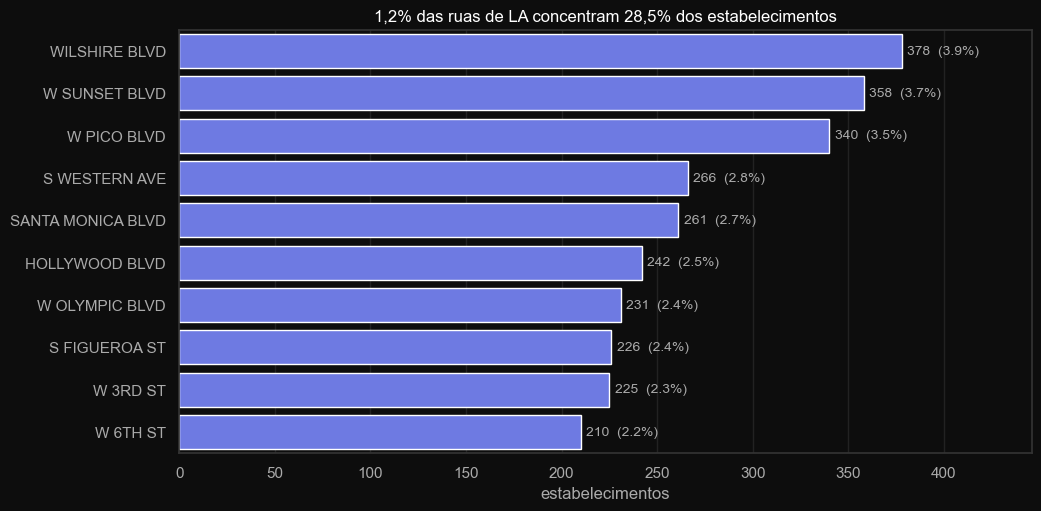

In [464]:
# Passo 3 — o gráfico. Mesma decisão do 2.1 e pelo mesmo motivo: comparação entre
# categorias vira barra, e nome de rua é texto longo, então barra HORIZONTAL —
# rótulo girado a 45° é ilegível em projetor. Ordenado por valor, sempre.
#
# Descartei a versão plotly aqui. A interatividade só agregaria se eu quisesse
# explorar além do top 10, e o enunciado fecha em dez. 

plt.figure(figsize=(11, 5.5))

ordem = top10.index.tolist()          # já vem decrescente do value_counts

ax = sns.barplot(
    data=top10.reset_index(),
    x='estabelecimentos',
    y='rua',
    order=ordem,
    color=CORES[0],
    orient='h',
)

rotulos = [f'{n}  ({p:.1f}%)'
        for n, p in zip(top10['estabelecimentos'], top10['proporcao_%'])]
ax.bar_label(ax.containers[0], labels=rotulos, padding=4, fontsize=10)

ax.set_xlim(0, top10['estabelecimentos'].max() * 1.18)
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
ax.set_xlabel('estabelecimentos')
ax.set_ylabel('')
ax.set_title('1,2% das ruas de LA concentram 28,5% dos estabelecimentos')

plt.savefig('images/2_7_top10_ruas.png')
plt.show()

In [465]:
# Afirmar sobre tipo de via precisa de número, senão é impressão minha olhando
# o gráfico. O tipo de via é a última palavra da coluna `rua`: a regra do 2.6 corta
# no tipo de via e descarta o que vem depois, então quem passou pela regra termina
# nele.

com_tipo = rest['rua'].drop_duplicates()
sem_tipo_via = ~com_tipo.str.contains(TIPO_RE, regex=True)
print('ruas distintas            : %d' % len(com_tipo))
print('sem tipo de via (excluídas): %d (%.1f%%)'
      % (sem_tipo_via.sum(), sem_tipo_via.mean() * 100))

# Duas contagens diferentes, e a comparação entre elas é o ponto: como os tipos de
# via se distribuem no TOP 10 contra como se distribuem na cidade inteira. Conto a
# cidade por rua DISTINTA, não por estabelecimento — a pergunta é sobre a malha
# viária, e contar por estabelecimento devolveria de novo a concentração do 2.7.
via_top10 = top10.index.str.split().str[-1].value_counts()
via_base = com_tipo[~sem_tipo_via].str.split().str[-1].value_counts()

via = pd.DataFrame({
    'no top 10': via_top10,
    'no top 10 %': via_top10 / via_top10.sum() * 100,
    'nas ruas da cidade %': via_base / via_base.sum() * 100,
}).loc[via_top10.index]

via['sobre-representação'] = via['no top 10 %'] / via['nas ruas da cidade %']
display(via.round(1))

print('\ntipos de via mais comuns na cidade:')
print((via_base / via_base.sum() * 100).head(5).round(5).to_string())


ruas distintas            : 810
sem tipo de via (excluídas): 44 (5.4%)


,no top 10,no top 10 %,nas ruas da cidade %,sobre-representação
rua,,,,
BLVD,6.0,60.0,21.9,2.7
ST,3.0,30.0,29.4,1.0
AVE,1.0,10.0,31.6,0.3



tipos de via mais comuns na cidade:
rua
AVE     31.59269
ST      29.37337
BLVD    21.93211
DR       7.18016
RD       2.48042


**📝 Conclusão 2.7 — ruas com mais restaurantes:**

**A resposta literal:** `WILSHIRE BLVD` lidera com 378 estabelecimentos (3,9% da base), seguida de
`W SUNSET BLVD` (358) e `W PICO BLVD` (340). O décimo lugar, `W 6TH ST`, tem 210.

**O número que importa não é nenhum desses.** É o que eles somam: dez ruas, de 810, concentram
2.737 estabelecimentos, **28,5% de todo o mercado de LA**. Pouco mais de 1% das ruas responde por
quase um terço da oferta. É essa a informação que muda uma decisão de localização; o ranking em si
é só o caminho até ela.

**O topo é parelho, não tem uma rua dominante.** Da primeira para a décima a queda é de 1,80x, 378
contra 210. Numa distribuição concentrada de verdade eu esperaria a líder disparada e a cauda
desabando logo atrás. Não é o caso. O que existe é um bloco de dez vias de peso parecido, e para a
decisão isso vale mais do que um líder isolado: não há um endereço único disputado, há um conjunto
de alternativas praticamente equivalentes.

**`BLVD` é apenas o terceiro tipo de via mais comum da cidade e concentra 60% do top 10.** Contando
ruas distintas, e deixando de fora as 44 (5,4%) que a regra do 2.6 não conseguiu classificar, `AVE`
responde por 31,6% da malha viária, `ST` por 29,4% e `BLVD` por 21,9%. No ranking a ordem se
inverte: seis das dez são `BLVD`, três são `ST` e uma é `AVE`. Em sobre-representação, `BLVD`
aparece 2,7x mais no topo do que na cidade, `ST` fica em 1,0x, exatamente a proporção esperada, e
`AVE` cai para 0,3x. A concentração de estabelecimentos não está espalhada ao acaso pela malha
viária, ela se concentra em boulevard.

**Uma ressalva sobre o que a contagem não diz.** "378 estabelecimentos na `WILSHIRE BLVD`" não quer
dizer 378 vizinhos de porta. O dado traz o nome da rua, não a coordenada, então não tenho como
saber se eles ocupam um trecho só ou estão distribuídos por toda a extensão da via. A contagem por
rua mede oferta, não vizinhança, e o passo 2.9 vai depender dessa distinção.

**A checagem que o 2.6 me obriga a fazer.** A coluna `rua` saiu de uma regra minha, não veio pronta
no dado, então o ranking podia estar contaminado por fragmento de extração. Todas as dez terminam
em tipo de via reconhecido pelo `TIPO_RE`, nenhuma é resíduo do parsing. O top 10 passa na checagem.

**Rua cheia é oportunidade ou risco?** A resposta depende de cheia do quê, e a comparação de mix é
o achado menos óbvio deste passo:

- **Café é 4,4% nas top 10 contra 4,5% no resto da cidade.** Praticamente idêntico. Os corredores
  não estão saturados de cafés, estão saturados de restaurantes (78,8% contra 73,8%).
- **Fast food é 7,6% nas top 10 contra 12,4% no resto**, quase metade. Rede também cai um pouco,
  36,2% contra 38,6%.
- Ou seja: o corredor não é outro mercado. É o mesmo mercado em escala maior, com o eixo deslocado
  na direção do restaurante de refeição completa.

**Análise crua:** para uma cafeteria, corredor pesa mais como oportunidade do
que como risco. O risco de concorrência direta seria real se a fatia de cafés ali fosse maior que a
da cidade, e ela não é, é a mesma. O que muda é o volume de gente exposta ao negócio. Se bem localizada geograficamente entre as ruas do top 10 ou no geral, pode vir a ser lucrativo.

### 2.8 Ruas com um único restaurante

> **Enunciado:** Encontre o número de ruas que têm apenas um restaurante.

É um número só, mas ele é o contrapeso do 2.7: junto, os dois descrevem se o mercado de LA é
concentrado em corredores ou pulverizado pela cidade.

In [466]:
# -----------------------------------------------------------------------------
# 2.8 Quantas ruas têm apenas um restaurante
# -----------------------------------------------------------------------------
# O enunciado pede um número. Um número sozinho engana: "374 ruas" é muito ou
# pouco? Entrego o absoluto e DOIS relativos, porque aqui eles contam histórias
# opostas e é justamente esse contraste que responde a pergunta da viabilidade do negócio.

vc_ruas = rest['rua'].value_counts()
solitarias = vc_ruas[vc_ruas == 1]

print('ruas distintas na base    : %d' % len(vc_ruas))
print('ruas com UM único estab.  : %d' % len(solitarias))
print()
print('sobre as RUAS       : %.1f%%' % (len(solitarias) / len(vc_ruas) * 100))
print('sobre os ESTABELEC. : %.1f%%' % (len(solitarias) / len(rest) * 100))

# A leitura que importa é a segunda. Quase metade das ruas da cidade tem um
# estabelecimento só, mas cada uma delas contribui com exatamente um, então todas
# juntas somam uma fatia pequena do mercado. Contar rua e contar oferta são
# perguntas diferentes, e responder a errada inverte a conclusão.

# Média contra mediana: o teste de assimetria mais barato que existe. Se a média
# for muito maior que a mediana, a distribuição tem cauda longa à direita e
# resumir esse mercado por "rua típica" não funciona.
print('\nestabelecimentos por rua  -> mediana: %.0f | média: %.1f'
    % (vc_ruas.median(), vc_ruas.mean()))

# O outro lado da mesma moeda, e o que amarra este passo ao 2.7: quantas ruas
# bastam para juntar metade e 80% da oferta da cidade.
acum = vc_ruas.cumsum() / len(rest)
for alvo in (0.50, 0.80):
    k = (acum < alvo).sum() + 1
    print('%d%% dos estabelecimentos cabem em %3d ruas (%.1f%% das ruas)'
          % (alvo * 100, k, k / len(vc_ruas) * 100))


ruas distintas na base    : 810
ruas com UM único estab.  : 374

sobre as RUAS       : 46.2%
sobre os ESTABELEC. : 3.9%

estabelecimentos por rua  -> mediana: 2 | média: 11.8
50% dos estabelecimentos cabem em  31 ruas (3.8% das ruas)
80% dos estabelecimentos cabem em 118 ruas (14.6% das ruas)


,ruas,estabelecimentos,% das ruas,% dos estabelecimentos
count,,,,
1,374,374,46.172840,3.899083
2,117,234,14.444444,2.439533
3 a 4,69,232,8.518519,2.418682
5 a 9,92,598,11.358025,6.234362
10 a 19,58,766,7.160494,7.985822
20 a 49,55,1679,6.790123,17.504170
50+,45,5709,5.555556,59.518349


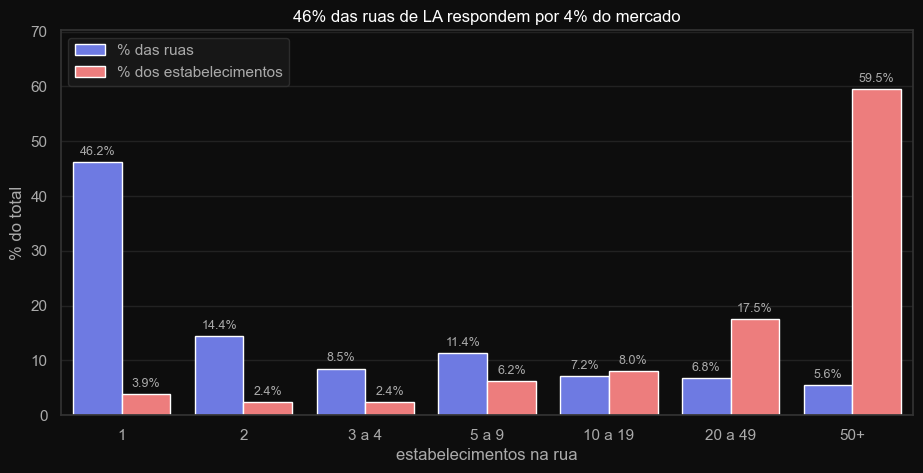

In [467]:
# O gráfico do 2.8 tem que mostrar a INVERSÃO, não a contagem. Um histograma
# simples de estabelecimentos por rua desenharia a cauda longa e pararia aí, e a
# cauda longa eu já provei com mediana 2 contra média 11,8. O que ainda não está
# desenhado é o contraste entre as duas leituras do mesmo recorte: a fatia das
# RUAS e a fatia dos ESTABELECIMENTOS. Por isso duas séries lado a lado.
#
# Faixas em vez do valor exato porque a cauda vai até 378 e uma barra por valor
# distinto viraria um pente ilegível. Corto fino embaixo (1, 2, 3-4), onde está a
# massa das ruas, e largo em cima, onde está a massa dos estabelecimentos.

faixas = [0, 1, 2, 4, 9, 19, 49, np.inf]
nomes = ['1', '2', '3 a 4', '5 a 9', '10 a 19', '20 a 49', '50+']

faixa_por_rua = pd.cut(vc_ruas, bins=faixas, labels=nomes)

dist = pd.DataFrame({
    'ruas': vc_ruas.groupby(faixa_por_rua, observed=False).size(),
    'estabelecimentos': vc_ruas.groupby(faixa_por_rua, observed=False).sum(),
})
dist['% das ruas'] = dist['ruas'] / dist['ruas'].sum() * 100
dist['% dos estabelecimentos'] = dist['estabelecimentos'] / dist['estabelecimentos'].sum() * 100
display(dist)

# Formato longo porque o seaborn desenha duas séries agrupadas a partir de uma
# coluna de categoria, não de duas colunas separadas.
longo = (dist[['% das ruas', '% dos estabelecimentos']]
        .rename_axis('faixa').reset_index()
        .melt(id_vars='faixa', var_name='leitura', value_name='pct'))

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=longo, x='faixa', y='pct', hue='leitura',
                palette=[CORES[0], CORES[1]])

for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', padding=3, fontsize=9)

ax.set_ylim(0, max(dist['% das ruas'].max(), dist['% dos estabelecimentos'].max()) * 1.18)
ax.set_xlabel('estabelecimentos na rua')
ax.set_ylabel('% do total')
ax.legend(title='')
ax.set_title('46% das ruas de LA respondem por 4% do mercado')

plt.savefig('images/2_8_ruas_vs_estabelecimentos.png')
plt.show()


In [468]:
# Adição extra

# O mesmo recorte do gráfico anterior, agora só para cafés. Repito a análise em
# vez de confiar no resultado geral porque o café é 4,4% da base: ele pode estar
# distribuído de um jeito completamente diferente do mercado que ele compõe, e é
# o café que decide este projeto.
#
# Diferença importante na montagem: aqui as ruas SEM café entram na conta. No
# gráfico anterior toda rua tinha pelo menos um estabelecimento, então a faixa
# zero não existia. Para café ela existe e é a maior de todas, então omiti-la
# inflaria todas as outras e esconderia justamente o espaço vazio do mercado.

cafes = rest[rest['object_type'] == 'Cafe']

cafes_por_rua = (cafes['rua'].value_counts()
                .reindex(rest['rua'].drop_duplicates(), fill_value=0))

faixas_c = [-1, 0, 1, 2, 4, 9, np.inf]
nomes_c = ['0', '1', '2', '3 a 4', '5 a 9', '10+']
faixa_cafe = pd.cut(cafes_por_rua, bins=faixas_c, labels=nomes_c)

dist_c = pd.DataFrame({
    'ruas': cafes_por_rua.groupby(faixa_cafe, observed=False).size(),
    'cafés': cafes_por_rua.groupby(faixa_cafe, observed=False).sum(),
})
dist_c['% das ruas'] = dist_c['ruas'] / dist_c['ruas'].sum() * 100
dist_c['% dos cafés'] = dist_c['cafés'] / dist_c['cafés'].sum() * 100
display(dist_c)

print('ruas sem nenhum café : %d de %d (%.1f%%)'
    % ((cafes_por_rua == 0).sum(), len(cafes_por_rua),
         (cafes_por_rua == 0).mean() * 100))


,ruas,cafés,% das ruas,% dos cafés
count,,,,
0,645,0,79.629630,0.000000
1,93,93,11.481481,21.830986
2,30,60,3.703704,14.084507
3 a 4,25,87,3.086420,20.422535
5 a 9,10,69,1.234568,16.197183
10+,7,117,0.864198,27.464789


ruas sem nenhum café : 645 de 810 (79.6%)


todos os tipos: ocupa 810 ruas | pegando uma amostra das 10% maiores concentram um valor de 72.8% da oferta
só cafés      : ocupa 165 ruas | pegando uma amostra das 10% maiores concentram um valor de 42.5% da oferta


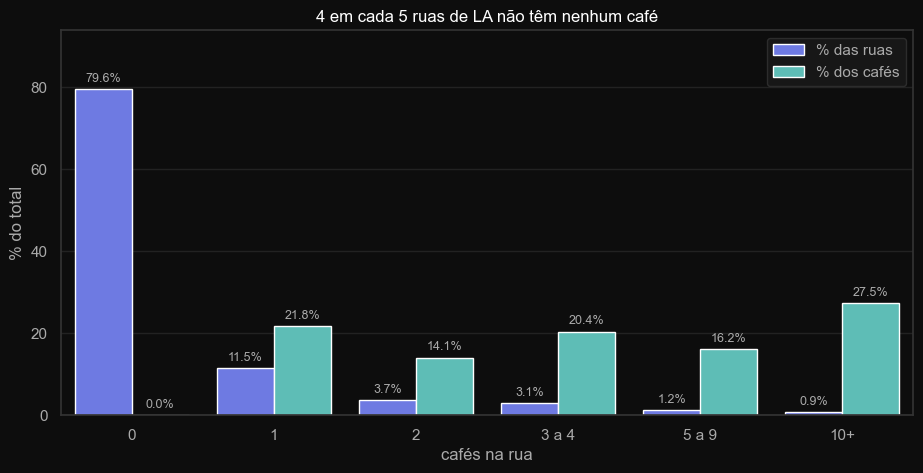

In [469]:
# Concentração comparável entre os dois mercados. Contar "quantas ruas juntam 50%
# da oferta" NÃO serve aqui: o café tem 426 unidades contra 9.592 do mercado
# inteiro, então ele alcança a própria metade com menos ruas só por ser menor, e
# não por estar mais apertado. A régua precisa ser relativa ao tamanho de cada um.
for rotulo, serie in [('todos os tipos', rest['rua'].value_counts()),
                    ('só cafés      ', cafes['rua'].value_counts())]:
    k = max(1, round(len(serie) * 0.10))
    print('%s: ocupa %3d ruas | pegando uma amostra das 10%% maiores concentram um valor de %.1f%% da oferta'
          % (rotulo, len(serie), serie.head(k).sum() / serie.sum() * 100))


longo_c = (dist_c[['% das ruas', '% dos cafés']]
        .rename_axis('faixa').reset_index()
        .melt(id_vars='faixa', var_name='leitura', value_name='pct'))

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=longo_c, x='faixa', y='pct', hue='leitura',
                palette=[CORES[0], CORES[3]])

for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', padding=3, fontsize=9)

ax.set_ylim(0, dist_c['% das ruas'].max() * 1.18)
ax.set_xlabel('cafés na rua')
ax.set_ylabel('% do total')
ax.legend(title='')
ax.set_title('4 em cada 5 ruas de LA não têm nenhum café')

plt.savefig('images/2_8_cafes_por_rua.png')
plt.show()

**📝 Conclusão 2.8 — ruas com um restaurante só:**

**A resposta literal:** 374 das 810 ruas têm um único estabelecimento, 46,2% da malha viária.

**O segundo relativo inverte a leitura.** Essas 374 ruas somam 374 estabelecimentos, 3,9% do
mercado. Quase metade das ruas de LA responde por menos de um vigésimo da oferta. Contar rua e
contar oferta são perguntas diferentes, e para quem vai investir só a segunda importa.

**O mercado é concentrado, não pulverizado.** Mediana de 2 estabelecimentos por rua contra média
de 11,8, um fator de seis que é assinatura de cauda longa. Na outra ponta, as ruas com 50 ou mais
estabelecimentos são 5,6% da malha e concentram 59,5% da oferta, a imagem espelhada das ruas
solitárias.

**Para o café a conta muda.** 645 ruas, 79,6% da cidade, não têm nenhum café: os 426 cabem em 165
ruas. Mas dentro dessas 165 a distribuição é bem mais plana. Com a mesma régua nos dois mercados,
o décimo mais movimentado das ruas ocupadas concentra 72,8% dos estabelecimentos em geral e apenas
42,5% dos cafés. Café é negócio que funciona espalhado, uma ou duas unidades por rua.

**O que isso fecha.** A rota "abrir numa rua tranquila para fugir da concorrência" está encerrada,
porque essas ruas somam 3,9% do mercado. A rota oposta, disputar endereço em corredor, o café não
exige, já que ele não segue o padrão de concentração do restaurante. Sobra uma faixa intermediária,
e dimensioná-la é trabalho do 2.9.


### 2.9 Distribuição de assentos nas ruas movimentadas

> **Enunciado:** Para as ruas com muitos restaurantes, olhe para a distribuição de número de
> assentos. Quais tendências você consegue notar?

Última pergunta e a mais aberta das nove — "muitos restaurantes" não tem definição no enunciado,
então o critério é meu e precisa estar escrito. É aqui que a recomendação de assentos ganha o
recorte geográfico.

In [470]:
# -----------------------------------------------------------------------------
# 2.9 Distribuição de assentos nas ruas com muitos restaurantes
# -----------------------------------------------------------------------------
# Antes de qualquer gráfico eu preciso definir "muitos restaurantes", e essa
# escolha é arbitrária por natureza: o enunciado não dá o corte. Em vez de eleger
# um e pedir confiança, testo quatro cortes defensáveis e mostro o efeito de cada
# um na resposta. Se a conclusão mudar conforme o corte, ela é do corte e não do
# mercado, e eu preciso saber disso agora e não depois de escrever a conclusão.

rest['n_rua'] = rest['rua'].map(vc_ruas)

criterios = {
    'top 10 do 2.7'   : rest['rua'].isin(top10.index),
    'top 10% das ruas': rest['rua'].isin(vc_ruas.head(round(len(vc_ruas) * 0.10)).index),
    '50 ou mais'      : rest['n_rua'] >= 50,
    '20 ou mais'      : rest['n_rua'] >= 20,
}

comp = pd.DataFrame({
    nome: {
        'ruas': rest.loc[m, 'rua'].nunique(),
        'estabelecimentos': m.sum(),
        '% da base': m.mean() * 100,
        'assentos: rua movimentada': rest.loc[m, 'number'].median(),
        'assentos: resto da cidade': rest.loc[~m, 'number'].median(),
    } for nome, m in criterios.items()
}).T

comp['diferença'] = comp['assentos: rua movimentada'] - comp['assentos: resto da cidade']
comp = comp.astype({'ruas': int, 'estabelecimentos': int}).round(1)
display(comp)


print('mediana de assentos na cidade inteira: %.0f' % rest['number'].median())


,ruas,estabelecimentos,% da base,assentos: rua movimentada,assentos: resto da cidade,diferença
top 10 do 2.7,10,2737,28.5,28.0,26.0,2.0
top 10% das ruas,81,6980,72.8,27.0,26.0,1.0
50 ou mais,45,5709,59.5,27.0,25.0,2.0
20 ou mais,100,7388,77.0,27.0,26.0,1.0


mediana de assentos na cidade inteira: 27


In [471]:
# A leitura: os quatro cortes cobrem de 10 a 100 ruas, de 28,5% a 77% da base, e
# entregam a mesma diferença de um ou dois assentos. A resposta é robusta ao
# critério, o que também significa que o efeito que eu procurava é pequeno.
# Fixo o top 10 do 2.7 daqui pra frente: já está definido, já foi apresentado, e
# com dez ruas o gráfico por rua da próxima célula continua legível.
movimentada = rest['rua'].isin(top10.index)

,rua movimentada,resto da cidade
count,2737.0,6855.0
mean,45.7,43.0
std,48.4,47.4
min,1.0,1.0
10%,6.0,6.0
25%,14.0,13.0
50%,28.0,26.0
75%,47.0,45.0
90%,126.0,118.0
max,229.0,229.0


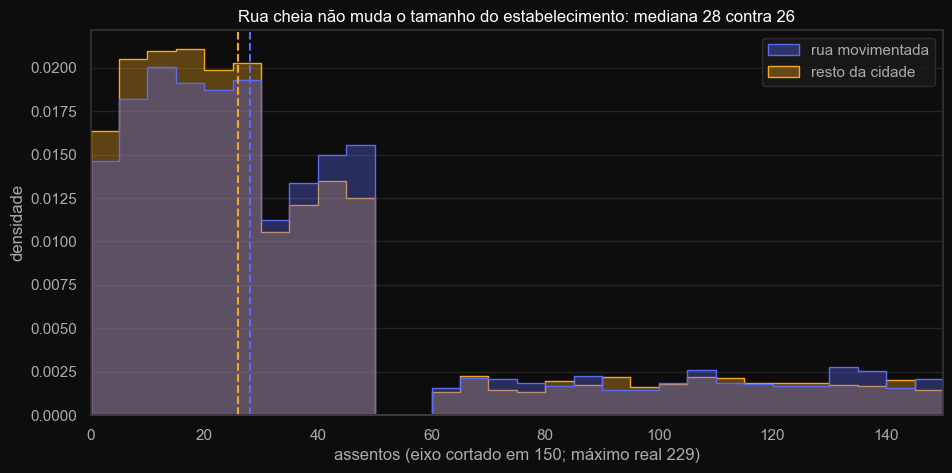

In [472]:
# A pergunta literal do enunciado: como os assentos se distribuem nas ruas
# movimentadas. Distribuição sozinha não é tendência, então desenho as duas,
# movimentada e resto da cidade, no mesmo eixo, e comparo.
#
# `stat='density'` com `common_norm=False`: os grupos têm 2.737 contra 6.855, e em
# contagem bruta eu estaria comparando tamanho de amostra em vez de formato.
#
# Eixo cortado em 150, motivo declarado: o máximo é 229, mas o percentil 90 dos
# dois grupos está em 126 e 118. Sem o corte, a faixa onde uma cafeteria vive
# fica espremida para acomodar uma cauda rala.
#
# Bin de 5 assentos, sem suavizar nada. Se houver furo na base ele aparece como
# zero no gráfico, e é assim que eu quero: prefiro ver o buraco a escondê-lo
# atrás de um KDE.

CORTE_X = 150

qtl = pd.DataFrame({
    'rua movimentada': rest.loc[movimentada, 'number'].describe(percentiles=[.1, .25, .5, .75, .9]),
    'resto da cidade': rest.loc[~movimentada, 'number'].describe(percentiles=[.1, .25, .5, .75, .9]),
}).round(1)
display(qtl)

plt.figure(figsize=(11, 5))

grupo = np.where(movimentada, 'rua movimentada', 'resto da cidade')

ax = sns.histplot(
    data=rest.assign(grupo=grupo), x='number', hue='grupo',
    stat='density', common_norm=False, bins=range(0, CORTE_X + 5, 5),
    element='step', fill=True, alpha=.35,
    palette=[CORES[0], CORES[2]], hue_order=['rua movimentada', 'resto da cidade'],
)

for cor, m in [(CORES[0], movimentada), (CORES[2], ~movimentada)]:
    ax.axvline(rest.loc[m, 'number'].median(), color=cor, ls='--', lw=1.5)

ax.set_xlim(0, CORTE_X)
ax.set_xlabel('assentos (eixo cortado em %d; máximo real 229)' % CORTE_X)
ax.set_ylabel('densidade')
ax.legend_.set_title('')
ax.set_title('Rua cheia não muda o tamanho do estabelecimento: mediana 28 contra 26')

plt.savefig('images/2_9_assentos_movimentada_vs_resto.png')
plt.show()

# As curvas respondem o enunciado: praticamente se sobrepõem. Mas apareceu uma
# coisa que eu não procurava. Perto de 50 assentos a densidade cai a zero nos
# DOIS grupos ao mesmo tempo, e volta depois num patamar bem mais baixo. Buraco
# igual nos dois grupos não é mercado, é o arquivo. Investigo antes de concluir.


In [473]:
# Investigando o buraco do gráfico acima. Não vou conferir a faixa que eu achei
# no olho: assento é contagem inteira, então varro todo o intervalo observado e
# pergunto quais inteiros não aparecem nenhuma vez. A base aponta, 
# talvez sejam números de assentos específicos.

faixa = range(int(rest['number'].min()), int(rest['number'].max()) + 1)
ausentes = [v for v in faixa if v not in set(rest['number'].unique())]

print('Assentos vão de %d a %d. Desses %d valores possíveis, %d não têm nenhum '
      'estabelecimento:' % (faixa.start, faixa.stop - 1, len(faixa), len(ausentes)))
print(' ', ausentes)

# Valor ausente solto é rarefação normal da cauda. Sequência longa de ausentes
# não acontece por acaso. Agrupo para separar um caso do outro.
blocos = []
for v in ausentes:
    if blocos and v == blocos[-1][-1] + 1:
        blocos[-1].append(v)
    else:
        blocos.append([v])

print('\nAgrupando os ausentes em sequências:')
for b in blocos:
    if len(b) == 1:
        print('  %3d           1 valor isolado' % b[0])
    else:
        print('  %3d a %3d    %2d valores seguidos   <- não acontece por acaso'
              % (b[0], b[-1], len(b)))

# O bloco maior corta a distribuição em dois. Num dado natural, os dois lados
# teriam densidade parecida.
maior = max(blocos, key=len)
lo, hi = maior[0], maior[-1]

print('\nO bloco de %d a %d parte a base em duas. Quantos estabelecimentos há,'
      ' em média,\npara cada número de assento de cada lado:' % (lo, hi))

lados = [('%d a %d' % (faixa.start, lo - 1), rest['number'] < lo, lo - faixa.start),
         ('%d a %d' % (hi + 1, faixa.stop - 1), rest['number'] > hi, faixa.stop - 1 - hi)]
dens = []
for rot, m, n_val in lados:
    dens.append(m.sum() / n_val)
    print('  %-9s (%3d valores): %5d estabelecimentos (%4.1f%%)  ->  %5.1f por assento'
          % (rot, n_val, m.sum(), m.mean() * 100, m.sum() / n_val))
print('  o lado de baixo é %.1fx mais denso que o de cima' % (dens[0] / dens[1]))

# Posso ter criado isso no passo 1, releio o arquivo original e rodo a mesma
# varredura. Se bater, a lacuna veio no dado.
cru = pd.read_csv(path)
ausentes_cru = [v for v in range(int(cru['number'].min()), int(cru['number'].max()) + 1)
                if v not in set(cru['number'].unique())]

print('\nA lacuna é do meu tratamento ou já vinha no arquivo?')
print('  arquivo original: %d linhas | base tratada: %d linhas (o Passo 1 tirou %d)'
      % (len(cru), len(rest), len(cru) - len(rest)))
print('  ausentes no arquivo original:', ausentes_cru)
print('  listas idênticas:', ausentes_cru == ausentes,
      ' -> a lacuna já estava no dado' if ausentes_cru == ausentes else ' -> fui eu')

Assentos vão de 1 a 229. Desses 229 valores possíveis, 13 não têm nenhum estabelecimento:
  [30, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 150]

Agrupando os ausentes em sequências:
   30           1 valor isolado
   50 a  60    11 valores seguidos   <- não acontece por acaso
  150           1 valor isolado

O bloco de 50 a 60 parte a base em duas. Quantos estabelecimentos há, em média,
para cada número de assento de cada lado:
  1 a 49    ( 49 valores):  7613 estabelecimentos (79.4%)  ->  155.4 por assento
  61 a 229  (169 valores):  1979 estabelecimentos (20.6%)  ->   11.7 por assento
  o lado de baixo é 13.3x mais denso que o de cima

A lacuna é do meu tratamento ou já vinha no arquivo?
  arquivo original: 9651 linhas | base tratada: 9592 linhas (o Passo 1 tirou 59)
  ausentes no arquivo original: [30, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 150]
  listas idênticas: True  -> a lacuna já estava no dado


quantidade_de_estabelecimentos                         mediana                
grupo                      resto da cidade rua movimentada resto da cidade rua movimentada
object_type                                                                               
Bakery                                 207              76            18.0            17.5
Pizza                                  217              97            16.0            24.0
Cafe                                   306             120            20.0            22.5
Fast Food                              851             209            22.0            20.0
Bar                                    214              78            28.5            29.5
Restaurant                            5060            2157            29.0            32.0

entre tipos: 18 a 29 assentos (11 de diferença)
entre ruas : 28 contra 26 assentos (2 de diferença)


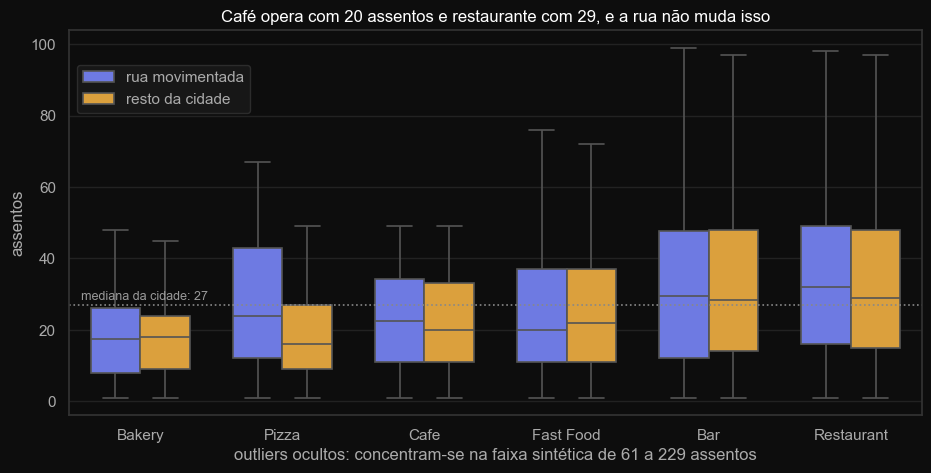

In [474]:
# A rua não explicou o tamanho do estabelecimento. Sobra a outra variável que eu
# tenho: o tipo. Ponho os dois no mesmo gráfico, tipo no eixo e rua na cor, para
# ver qual dos dois move os assentos.
#
# Boxplot e não violino. O violino desenharia a lacuna de 50 a 60 como se fossem
# duas famílias de estabelecimento, e a célula acima já mostrou que aquilo é do
# arquivo. O box mostra mediana e quartis, que caem todos abaixo de 50 e não
# dependem do bloco sintético.
#
# `showfliers=False` com o motivo declarado no eixo: os pontos além do terceiro
# quartil vivem quase todos na faixa de 61 a 229, a parte rala e artificial da
# base. Desenhá-los daria peso visual justamente ao que menos merece confiança.

grupo_rua = np.where(movimentada, 'rua movimentada', 'resto da cidade')

ordem_tipo = (rest.groupby('object_type', observed=True)['number']
            .median().sort_values().index.tolist())

resumo = (rest.assign(grupo=grupo_rua)
        .groupby(['object_type', 'grupo'], observed=True)['number']
        .agg(quantidade_de_estabelecimentos='size', mediana='median').unstack('grupo').loc[ordem_tipo])
display(resumo)

# Os dois efeitos em número, que é o que o título afirma.
med_tipo = rest.groupby('object_type', observed=True)['number'].median()
print('entre tipos: %d a %d assentos (%d de diferença)'
    % (med_tipo.min(), med_tipo.max(), med_tipo.max() - med_tipo.min()))
print('entre ruas : %d contra %d assentos (%d de diferença)'
    % (rest.loc[movimentada, 'number'].median(),
    rest.loc[~movimentada, 'number'].median(),
        rest.loc[movimentada, 'number'].median() - rest.loc[~movimentada, 'number'].median()))

plt.figure(figsize=(11, 5))

ax = sns.boxplot(
    data=rest.assign(grupo=grupo_rua),
    x='object_type', y='number', hue='grupo', order=ordem_tipo,
    hue_order=['rua movimentada', 'resto da cidade'],
    palette=[CORES[0], CORES[2]], showfliers=False, width=.7, linewidth=1.2,
)

med_cidade = rest['number'].median()
ax.axhline(med_cidade, color='#888888', ls=':', lw=1.2)
ax.text(-.42, med_cidade + 1.5, 'mediana da cidade: %d' % med_cidade,
        fontsize=9, color='#999999')

ax.set_xlabel('outliers ocultos: concentram-se na faixa sintética de 61 a 229 assentos')
ax.set_ylabel('assentos')
ax.legend(title='', loc='upper left', bbox_to_anchor=(0, .93))
ax.set_title('Café opera com 20 assentos e restaurante com 29, e a rua não muda isso')

plt.savefig('images/2_9_assentos_por_tipo_e_rua.png')
plt.show()


**📝 Conclusão 2.9 — assentos nas ruas movimentadas:**

**O critério.** Rua movimentada é o top 10 do 2.7. Testei quatro cortes antes de fixar, de 10 a 100
ruas, cobrindo de 28,5% a 77% da base, e os quatro deram a mesma resposta. A escolha não carrega a
conclusão.

**A distribuição.** Nas ruas movimentadas a mediana é 28 assentos, com quartis em 14 e 47. No resto
da cidade é 26, com quartis em 13 e 45. Não coincide só o centro: p10, q1, mediana, q3 e p90 batem
quase valor a valor.

**A tendência que o enunciado pede não existe nesse eixo.** Dois assentos de diferença, com os
quatro critérios concordando. Rua cheia não faz o estabelecimento nem menor nem maior.

**O que explica o tamanho é o tipo.** A mediana vai de 18 assentos na `Bakery` a 29 no `Restaurant`,
11 de diferença. Entre ruas, 2. No boxplot as duas caixas de cada tipo ficam coladas, e o que separa
é a posição do tipo no eixo, não a cor.

**Onde isso deixa o café.** Mediana de 22,5 assentos nas ruas movimentadas e 20 no resto, apurada em
120 e 306 casos. É a quarta menor das seis categorias, e a diferença entre os dois cenários é de
dois assentos e meio. Ou seja, mudar de endereço não muda o projeto da loja.

**O que este passo direciona.** Duas decisões saem daqui. A de assentos deixa de depender de
localização e passa a se apoiar no tipo: a faixa do café é 20 a 22,5 de mediana, e é com o 2.5
(metade dos cafés entre 11 e 34) e o 2.4 (Starbucks com 25, Coffee Bean com 22) que ela fecha na
seção 3. A de endereço perde um argumento: pagar caro por corredor esperando operação diferente não
se sustenta, porque a operação é a mesma dentro e fora dele.

**O que este dado não permite afirmar.** A varredura achou 13 valores de assento sem nenhum
registro, 11 deles seguidos, de 50 a 60. Abaixo da lacuna cada número de assento carrega 155
estabelecimentos, acima carrega 12, treze vezes menos. A mesma lista aparece no arquivo original,
então não é efeito do Passo 1. Por isso trabalho com mediana e não com média, e não leio as duas
massas do histograma como bimodalidade de mercado, porque elas são do arquivo.



---

# 3. Conclusão geral e recomendações

> **Enunciado:** Tire uma conclusão geral e apresente recomendações sobre o tipo mais apropriado de
> restaurante e o número de assentos. Comente sobre a possibilidade de desenvolver uma rede.

**A resposta, em três linhas.** Abrir a cafeteria com **20 a 25 assentos**. O formato café é o que
mais vira rede em LA, então tratar a expansão como plano desde o início, e não como consequência.
Não disputar endereço em corredor: para café, a rua não muda o resultado.

## 3.1 O que o mercado de LA mostra

- **Café é categoria pequena, mas não marginal.** 426 estabelecimentos, 4,4% do mercado, terceiro
  entre seis tipos e o maior da cauda. O mercado é de restaurantes: 75,2% (2.1).
- **Café é o formato que mais vira rede.** 60,6% dos cafés pertencem a alguma rede, contra 37,9% da
  cidade, e a marca de café tem 4,53 unidades em média, a maior replicação de todos os tipos
  (2.2, 2.3).
- **Tamanho de rede e tamanho de loja são independentes.** Correlação de Pearson de -0,001 e de
  Spearman de 0,019. Crescer em unidades não exige loja maior (2.4).
- **Café é o formato mais previsível dos seis.** Único tipo com dispersão menor que a própria média
  (0,86). Metade dos cafés opera entre 11 e 34 assentos (2.5).
- **A localização não move o tamanho.** Rua movimentada tem mediana de 28 assentos contra 26 no
  resto da cidade, com quatro critérios de corte concordando (2.9).

## 3.2 Recomendação de tipo de estabelecimento

**Café, e o dado sustenta a escolha por dois motivos independentes.** É o tipo com maior taxa de
rede (60,6%) e maior replicação por marca (4,53 unidades), o que responde à pergunta de escala; e é
o mais homogêneo dos seis (dispersão 0,86), o que significa que existe um padrão real de operação a
copiar, e não uma média calculada sobre coisas incomparáveis (2.3, 2.5).

O contraponto honesto: café é 4,4% do mercado. Essa fatia pequena admite duas leituras opostas,
nicho pouco explorado ou categoria que o mercado não sustenta, e **esta base não separa as duas**,
porque não tem faturamento nem tempo de operação (2.1).

## 3.3 Recomendação de número de assentos

**De 20 a 25 assentos.** A faixa vem de três medidas que convergem:

| evidência | valor | passo |
|---|---|---|
| mediana dos cafés de LA | 20 assentos | 2.5 |
| mediana dos cafés em rua movimentada | 22,5 assentos | 2.9 |
| as duas redes de café que escalaram | Starbucks 25, Coffee Bean 22 | 2.4 |

O piso é o café mediano da cidade. O teto é o tamanho com que a maior rede de café de LA chegou a
119 unidades. Metade dos cafés cabe entre 11 e 34 assentos, então 20 a 25 fica no centro da faixa
de mercado, e não na borda (2.5).

Uso mediana e não média em toda esta seção. A coluna de assentos não tem nenhum registro entre 50 e
60, e abaixo dessa lacuna cada valor carrega 155 estabelecimentos contra 12 acima. A média é
inflada por esse bloco, a mediana não (2.9).

## 3.4 Possibilidade de desenvolver uma rede

**Recomendo, com uma condição.** O mercado comporta: 37,9% dos estabelecimentos de LA são de rede, e
café é o tipo que mais escala (2.2, 2.3). E o formato pequeno não atrapalha, já que Starbucks chegou
a 119 unidades com 25 assentos medianos (2.4).

A condição vem do achado menos confortável do projeto: **não existe camada intermediária**. Das 57
marcas de café de rede, duas concentram 67,4% das unidades, e 40 têm uma loja só. O espaço entre 1 e
119 unidades está praticamente vazio (2.3). Crescer devagar até virar rede média não é um caminho
observável na cidade. A decisão precisa de um gatilho definido desde já: quantas unidades em quanto
tempo, com o capital reservado antes da primeira, porque o meio do caminho não aparece nos dados.

## 3.5 Limitações da análise

- **É uma foto, não uma série.** Não há data, faturamento, tráfego de pedestres nem aluguel. A base
  mostra onde a oferta está, não onde a demanda existe. Toda leitura de "rua vazia é rua sem
  mercado" é inferência minha, não medição (2.8).
- **A coluna de assentos é sintética.** 13 valores sem nenhum registro, 11 deles seguidos de 50 a
  60, confirmados no arquivo original. Por isso não trato as duas massas do histograma como
  bimodalidade de mercado (2.9).
- **A flag de rede é declarada na fonte.** Não é derivada dos dados, e as 283 padarias marcadas como
  rede com 249 marcas distintas provam que o critério não é uniforme entre tipos (1.3, 2.3).
- **A coluna de rua é resultado de uma regra minha.** 5,4% das ruas ficaram sem tipo de via
  identificável (2.6, 2.7).
- **A recomendação de assentos apoia-se em 426 cafés**, não nos 9.592 estabelecimentos da base.
- Correlação observada é descrição do mercado de LA, não prova de causa.

## 3.6 Próximos passos do cliente e das futuras análises

1. **Faturamento por estabelecimento.** É o dado que separa "nicho pouco explorado" de "categoria
   que não se sustenta", a ambiguidade que atravessa o projeto inteiro (2.1).
2. **Fluxo de pedestres e aluguel por metro quadrado nas ruas candidatas.** Sem eles, a escolha de
   endereço fica apoiada em densidade de oferta, que é proxy fraco de demanda (2.7, 2.8).
3. **Custo operacional dos garçons robôs por assento.** Define se 20 a 25 assentos fecha a conta, e
   é a única variável da decisão que não está nesta base.


---

# 4. Apresentação

> **Enunciado:** Faça uma apresentação da pesquisa pros investidores. Qualquer ferramenta, com
> conversão final para PDF.

O deck completo está no repositório, em
[`presentation/Sprint10-apresentacao-mercado-restaurantes-LA.pdf`](https://github.com/luiz19190/Sprint10-mercado-de-restaurantes-LA/blob/main/presentation/Sprint10-apresentacao-mercado-restaurantes-LA.pdf).
Estrutura:
Situação → Complicação → Resolução, com os títulos já no formato "título entrega a conclusão".
Os gráficos exportados por este notebook ficam em `images/`.

São oito slides, e cada um responde a um passo desta análise:

| slide | título | vem de |
|---|---|---|
| 1 | Cafeteria com garçons robôs em Los Angeles: o que o mercado suporta | capa |
| 2 | LA é uma cidade de restaurantes: 3 em cada 4 estabelecimentos | 2.1 |
| 3 | Café é o formato que mais vira rede em LA: 60,6% contra 37,9% da cidade | 2.2, 2.3 |
| 4 | Não existe rede de café média em LA: ou 1 loja, ou 119 | 2.3 |
| 5 | 46% das ruas de LA respondem por 4% do mercado | 2.7, 2.8 |
| 6 | Quem define o tamanho da loja é o tipo, não a rua: 11 assentos contra 2 | 2.9 |
| 7 | Abrir com 20 a 25 assentos e tratar rede como plano, não como consequência | 2.4, 2.5, 2.9 |
| 8 | Três dados que faltam antes de assinar o cheque | 3.5, 3.6 |

---

Presentation: https://drive.google.com/file/d/1EN0M_T7A-hg6Hgacp2DOKKBLTVOF1IT3/view?usp=drive_link